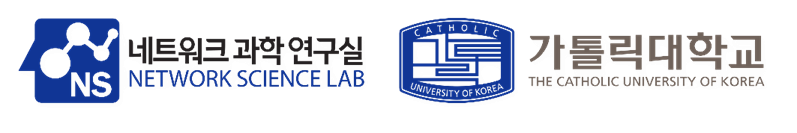

# Practice Code 12: Spatial-Temporal GNNs

Every node carries a time series: the graph is fixed, but the signal on it changes from frame to frame. 

Our task is skeleton-based action recognition. A depth camera or a pose estimator turns every video frame into the 3-D coordinates of the body joints. 

The joints are the nodes, the bones are the edges, and a clip is a sequence of such graphs. A spatio-temporal GNN (STGNN) has to model which joints move together (space) and how they move (time).

| Lecture part | Section | What we build |
|:--|:--|:--|
| Motivation | 1 | the data (daily actions as skeleton sequences), the skeleton graph, a cross-view split, reference models |
| An overview of STGNNs | 2 | product graphs, the encoder → STMP → readout recipe, Time-then-Space, Space-then-Time and Time-and-Space models (GCRNN, STCN, product-graph GCN) |
| ST-GCN | 3 | partition strategies, learnable edge importance |
| 2s-AGCN | 4 | adaptive graph $A_k + B_k + C_k$, bone stream, two-stream fusion |
| AS-GCN | 5 | S-links, A-link inference, future-pose prediction head |
| MS-G3D | 6 | biased vs. disentangled multi-scale aggregation, G3D cross-spacetime edges |
| DG-STGCN | 7 | hypergraphs: incidence matrix, limb, adjacent-joint and temporal hyperedges |
| Comparison | 8 | all models side by side |

# 0. Setup

In [1]:
INSTALL_DEPENDENCIES = False

if INSTALL_DEPENDENCIES:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "torch", "numpy", "matplotlib"])

In [2]:
import os, json, glob, math, time, random, warnings
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(0)
DATA_DIR = "./dataset"                                     # NW-UCLA, views 1 and 2
COLORS = {'Reference': '#9a9a9a', 'Paradigm': '#2a78d6', 'ST-GCN': '#1baf7a', '2s-AGCN': '#e34948',
          'AS-GCN': '#eda100', 'MS-G3D': '#6250d6', 'Hypergraph': '#e87ba4', 'Data': '#0b0b0b'}

Device: cuda


# 1. The data: daily actions as skeleton sequences

## 1.1. NW-UCLA skeletons

Northwestern-UCLA Multiview Action 3D dataset, a standard benchmark of skeleton-based action recognition. 

10 subjects perform 10 daily actions, several times each. Every performance is filmed simultaneously by three Kinect cameras placed at different viewpoints. 

The Kinect software estimates 20 joints in 3-D for every frame, in the coordinate system of its camera (metres; $x$ horizontal, $y$ up, $z$ the distance to the camera).

Every JSON file is one clip, recorded by one camera. The file name encodes the recording, `a<action>_s<subject>_e<repetition>_v<view>`, and the key `skeletons` holds a list of $T$ frames × 20 joints × $(x, y, z)$. $T$ differs from clip to clip.

| code | action | code | action |
|:--|:--|:--|:--|
| a01 | pick up with one hand | a06 | stand up |
| a02 | pick up with two hands | a08 | donning (put on a jacket) |
| a03 | drop trash | a09 | doffing (take off a jacket) |
| a04 | walk around | a11 | throw |
| a05 | sit down | a12 | carry |

In [3]:
V = 20                                                     # Kinect v1 joints
JOINT_NAMES = ['hip centre', 'spine', 'shoulder centre', 'head', 'L shoulder', 'L elbow', 'L wrist', 'L hand',
               'R shoulder', 'R elbow', 'R wrist', 'R hand', 'L hip', 'L knee', 'L ankle', 'L foot',
               'R hip', 'R knee', 'R ankle', 'R foot']
ACTION_CODES = ['a01', 'a02', 'a03', 'a04', 'a05', 'a06', 'a08', 'a09', 'a11', 'a12']
ACTIONS = ['pick up (one hand)', 'pick up (two hands)', 'drop trash', 'walk around', 'sit down',
           'stand up', 'donning', 'doffing', 'throw', 'carry']
NUM_CLASS = len(ACTIONS)

def load_folder(root):
    # Every JSON file of root: name, action (0-9), subject, repetition, view, x [T, V, 3]
    clips = []
    for path in sorted(glob.glob(os.path.join(root, '*.json'))):
        name = os.path.basename(path)[:-5]
        a, s, e, v = name.split('_')
        with open(path) as f:
            x = np.array(json.load(f)['skeletons'], dtype=np.float32)    # [T, 20, 3]
        clips.append(dict(name=name, act=ACTION_CODES.index(a), subj=int(s[1:]), rep=int(e[1:]), view=int(v[1:]), x=x))
    return clips

CLIPS = load_folder(DATA_DIR)
CLIP = {c['name']: c for c in CLIPS}
print(f'{len(CLIPS)} clips | subjects {sorted({c["subj"] for c in CLIPS})} | one clip: T frames x {V} joints x 3 coordinates\n')
print(f"{'clips':<22}{'view 1':>8}{'view 2':>8}{'total':>8}")
for a, name in enumerate(ACTIONS):
    row = [sum(c['act'] == a and c['view'] == v for c in CLIPS) for v in (1, 2)]
    print(f'{name:<22}{row[0]:>8}{row[1]:>8}{sum(row):>8}')
print(f"{'total':<22}" + ''.join(f'{sum(c["view"] == v for c in CLIPS):>8}' for v in (1, 2)) + f'{len(CLIPS):>8}')

1020 clips | subjects [1, 2, 3, 4, 5, 6, 7, 8, 9, 10] | one clip: T frames x 20 joints x 3 coordinates

clips                   view 1  view 2   total
pick up (one hand)          53      49     102
pick up (two hands)         52      50     102
drop trash                  51      45      96
walk around                 64      60     124
sit down                    50      51     101
stand up                    52      50     102
donning                     49      50      99
doffing                     50      49      99
throw                       49      49      98
carry                       46      51      97
total                      516     504    1020


## 1.2. Clip lengths and camera views

Two properties of the data shape everything that follows: the clips have different lengths, and every camera measures the joints in its own coordinate system.

view 1: frames per clip min 6, median 40, max 201 | clips with < 10 frames: 3
view 2: frames per clip min 1, median 28, max 146 | clips with < 10 frames: 3


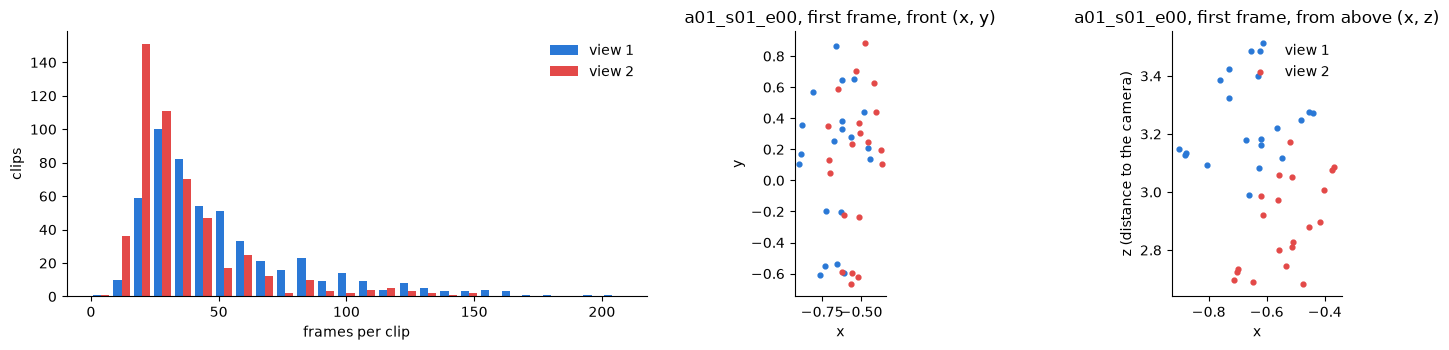

In [4]:
LENGTHS = np.array([len(c['x']) for c in CLIPS])
VIEW = np.array([c['view'] for c in CLIPS])
for v in (1, 2):
    L = LENGTHS[VIEW == v]
    print(f'view {v}: frames per clip min {L.min()}, median {np.median(L):.0f}, max {L.max()} | clips with < 10 frames: {(L < 10).sum()}')

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), gridspec_kw=dict(width_ratios=[1.3, 1, 1]))
axes[0].hist([LENGTHS[VIEW == 1], LENGTHS[VIEW == 2]], bins=range(0, 210, 8), label=['view 1', 'view 2'],
             color=[COLORS['Paradigm'], COLORS['2s-AGCN']])
axes[0].set(xlabel='frames per clip', ylabel='clips'); axes[0].legend(frameon=False)
axes[0].spines[['top', 'right']].set_visible(False)

# The same performance (subject 1 picks something up) seen by the two cameras: first frame of each clip
for v, col in [(1, COLORS['Paradigm']), (2, COLORS['2s-AGCN'])]:
    pose = CLIP[f'a01_s01_e00_v0{v}']['x'][0]
    for ax, (i, j), title in [(axes[1], (0, 1), 'front (x, y)'), (axes[2], (0, 2), 'from above (x, z)')]:
        ax.scatter(pose[:, i], pose[:, j], s=12, color=col, label=f'view {v}')
        ax.set(xlabel='x', ylabel='y' if j == 1 else 'z (distance to the camera)', title=f'a01_s01_e00, first frame, {title}')
axes[2].legend(frameon=False)
for ax in axes[1:]: ax.set_aspect('equal'); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

* The clips have very different lengths: 6 to 201 frames in view 1 (median 40) and 1 to 146 frames in view 2 (median 28). Six clips have fewer than 10 frames, and one has a single frame. The two clips of a performance are not cut in the same way, so frame $t$ of view 1 is not frame $t$ of view 2. A network that processes all clips in one tensor needs a fixed number of frames.

* The same pose has different coordinates in the two cameras. View 2 is closer to the subject ($z$ ≈ 2.7–3.2 m instead of 3.0–3.5 m), and the skeleton is rotated about the vertical axis. Over all performances filmed by both cameras, the shoulder line turns by about 24° in the median, with a large spread from clip to clip.

* A model trained on one view must therefore recognise the actions in coordinates translated and rotated by amounts it has never seen. We centre every clip, and we augment the training clips with random rotations about the vertical axis.

## 1.3. The skeleton graph

Every frame is a graph: nodes = the 20 joints, edges = the 19 bones of the Kinect skeleton (spine, arms with hands, legs with feet). The skeleton is a tree rooted at the hip centre.

Kinect skeleton:   19 edges, 1 connected component (a tree: V - 1 = 19 edges)
kNN graph (k = 2): 27 edges, 13 of them are bones, 2 connected components


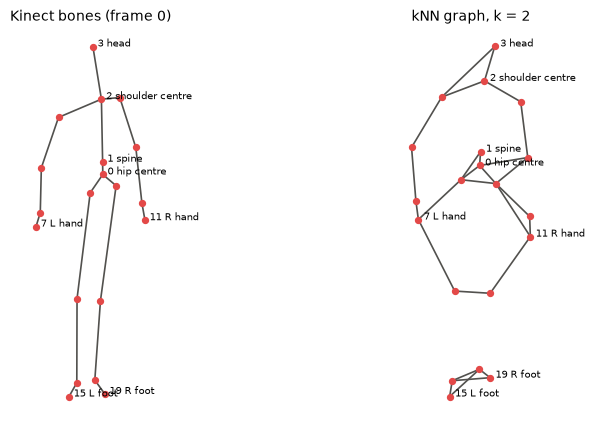

In [5]:
BONES = [(0, 1), (1, 2), (2, 3),                                       # spine and head
         (2, 4), (4, 5), (5, 6), (6, 7),                               # left arm
         (2, 8), (8, 9), (9, 10), (10, 11),                            # right arm
         (0, 12), (12, 13), (13, 14), (14, 15),                        # left leg
         (0, 16), (16, 17), (17, 18), (18, 19)]                        # right leg

def adjacency(edges, n=V):
    A = torch.zeros(n, n)
    for i, j in edges:
        A[i, j] = A[j, i] = 1.0
    return A

def normalize_adj(A, self_loops=True):
    # D^-1/2 (A + I) D^-1/2 
    if self_loops:
        A = A + torch.eye(A.size(0))
    d = A.sum(1).clamp(min=1e-6).pow(-0.5)
    return d[:, None] * A * d[None, :]

def knn_edges(pose, k=2):
    # Every joint linked to its k nearest joints in the pose
    dist = np.linalg.norm(pose[None] - pose[:, None], axis=-1)
    return sorted({tuple(sorted((i, int(j)))) for i in range(len(pose)) for j in np.argsort(dist[i])[1:k + 1]})

def n_components(A):
    L = torch.diag(A.sum(1)) - A
    return int((torch.linalg.eigvalsh(L) < 1e-5).sum())

A_SKEL = adjacency(BONES)
mean_pose = CLIP['a01_s01_e00_v01']['x'].mean(0)
KNN = knn_edges(mean_pose, k=2)
bones = {frozenset(e) for e in BONES}
print(f'Kinect skeleton:   {len(BONES)} edges, {n_components(A_SKEL)} connected component (a tree: V - 1 = {V - 1} edges)')
print(f'kNN graph (k = 2): {len(KNN)} edges, {sum(frozenset(e) in bones for e in KNN)} of them are bones, '
      f'{n_components(adjacency(KNN))} connected components')

frame = CLIP['a01_s01_e00_v01']['x'][0]
fig, axes = plt.subplots(1, 2, figsize=(9, 5))
for ax, edges, pose, title in [(axes[0], BONES, frame, 'Kinect bones (frame 0)'), (axes[1], KNN, mean_pose, 'kNN graph, k = 2')]:
    for i, j in edges:
        ax.plot(pose[[i, j], 0], pose[[i, j], 1], color='#52514e', lw=1.2)
    ax.scatter(pose[:, 0], pose[:, 1], s=18, color=COLORS['2s-AGCN'], zorder=3)
    for i in [0, 1, 2, 3, 7, 11, 15, 19]:
        ax.text(pose[i, 0] + 0.02, pose[i, 1], f'{i} {JOINT_NAMES[i]}', fontsize=7)
    ax.set_aspect('equal'); ax.set_title(title, fontsize=10); ax.axis('off')
plt.show()

* The Kinect skeleton is a tree with 19 bones and one connected component. The trunk (hip centre – spine – shoulder centre) links the four limbs and the head.

* The kNN graph has 27 edges, but only 13 of them are bones. It creates triangles around the hips and the shoulders. In the mean pose of a "pick up" clip the hands come close to the knees, so it links hands and legs. It also falls apart into 2 components: the two feet form a separate triangle, and no message can travel between them and the body.

## 1.4. Preprocessing, a cross-view split and the training protocol

Preprocessing. 

(1) Every clip is resampled to $T = 52$ frames by linear interpolation in time, as in the NW-UCLA code of CTR-GCN. Long clips are subsampled and short clips are stretched, so that all clips fit in one tensor. 

(2) We subtract the position of the spine joint in the first frame, so that every clip starts at the origin while the movement of the body relative to it (e.g. walking) is kept.

Split. 

Every performance is filmed by several cameras. 

A random split of the files would put one view of a performance in the training set and another view of the same performance in the test set. 

We use the cross-view protocol instead: train on all clips of one view and test on the other view (two folds: 1 → 2 and 2 → 1). 

The test camera has a viewpoint that the model has never seen. 

In [6]:
T_FRAMES = 52

def resample(x, T=T_FRAMES):
    # linear interpolation of a clip [T0, V, 3] to T frames
    pos = np.linspace(0, len(x) - 1, T)
    lo = np.floor(pos).astype(int)
    hi = np.minimum(lo + 1, len(x) - 1)
    w = (pos - lo)[:, None, None]
    return x[lo] * (1 - w) + x[hi] * w

def preprocess(x, T=T_FRAMES):
    x = resample(x, T)                                                  # ★ KEY: every clip has T frames
    return (x - x[0, 1]).astype(np.float32)                             # ★ KEY: origin = spine joint of the first frame

X_ALL = torch.tensor(np.stack([preprocess(c['x']) for c in CLIPS]))     # [1020, T=52, V=20, C=3]
Y_ALL = torch.tensor([c['act'] for c in CLIPS])
TEST_VIEWS = [1, 2]
print('X_ALL:', tuple(X_ALL.shape), '| coordinate range after preprocessing:', f'[{X_ALL.min():.2f}, {X_ALL.max():.2f}] m')

# How often does a random file-level split leak a performance?
perf = [(c['act'], c['subj'], c['rep']) for c in CLIPS]          # a performance = (action, subject, repetition)
views_of = {}
for i, p in enumerate(perf):
    views_of.setdefault(p, []).append(i)
leaks = []
for seed in range(20):
    test = np.random.default_rng(seed).permutation(len(CLIPS))[:len(CLIPS) // 5]   # 80 / 20 split of the files
    test_set = set(test.tolist())
    leaks.append(np.mean([any(j not in test_set for j in views_of[perf[i]] if j != i) for i in test]))
print(f'{len(views_of)} performances, {sum(len(v) == 2 for v in views_of.values())} of them filmed by both cameras 1 and 2')
print(f'random 80/20 split of the files: {np.mean(leaks):.1%} of the test clips have the other view of their performance in the training set')

X_ALL: (1020, 52, 20, 3) | coordinate range after preprocessing: [-3.14, 3.14] m
542 performances, 478 of them filmed by both cameras 1 and 2
random 80/20 split of the files: 76.4% of the test clips have the other view of their performance in the training set


Training protocol:

* Adam, learning rate $10^{-3}$, weight decay $10^{-4}$, cosine schedule, 40 epochs, batches of 32 clips.

* Data augmentation: a random rotation about the vertical axis by up to ±60° ($\pi/3$), which imitates a camera at another position, and a random scaling by up to ±10%.

* The three recurrent models use a learning rate of $3\cdot10^{-3}$.

* Every model gets a `DataBN` layer first: a batch normalisation of every (joint, coordinate) channel, as in ST-GCN.

* Score = accuracy averaged over the 2 cross-view folds; we repeat the whole procedure with 3 seeds and report mean ± std over the seeds. A test fold has about 510 clips, so one clip is worth 0.2% accuracy, and the seed-to-seed spread tells us which differences are noise.

In [7]:
EPOCHS = 40
ROTATION = math.pi / 3                                         # radians

def augment(x, rot=ROTATION, scale=0.1):
    # random rotation about the vertical (y) axis and random scaling, one per clip.  x: [N, T, V, C]
    n = x.size(0)
    theta = (torch.rand(n, device=x.device) * 2 - 1) * rot
    c, s = torch.cos(theta)[:, None, None], torch.sin(theta)[:, None, None]
    x = torch.stack([c * x[..., 0] + s * x[..., 2], x[..., 1], -s * x[..., 0] + c * x[..., 2]], -1)
    return x * (1 + scale * (torch.rand(n, 1, 1, 1, device=x.device) * 2 - 1))

class DataBN(nn.Module):
    # BatchNorm over the C*V channels of the input, then reshape [N, T, V, C] -> [N, C, T, V] (the ST-GCN layout)
    def __init__(self, C=3, n=V):
        super().__init__()
        self.bn = nn.BatchNorm1d(C * n)
    def forward(self, x):
        N, T, n, C = x.shape
        x = self.bn(x.permute(0, 2, 3, 1).reshape(N, n * C, T))
        return x.view(N, n, C, T).permute(0, 2, 3, 1)

def n_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def train_model(model, X, y, epochs=EPOCHS, lr=1e-3, weight_decay=1e-4, batch_size=32, loss_fn=None):
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    X, y = X.to(device), y.to(device)
    for epoch in range(epochs):
        model.train()
        perm = torch.randperm(len(X), device=device)
        for i in range(0, len(X), batch_size):
            idx = perm[i:i + batch_size]
            xb = augment(X[idx])
            loss = F.cross_entropy(model(xb), y[idx]) if loss_fn is None else loss_fn(model, xb, y[idx])
            opt.zero_grad(); loss.backward(); opt.step()
        sched.step()
    return model

@torch.no_grad()
def predict(model, X, batch_size=128):
    model.eval()
    return torch.cat([F.softmax(model(X[i:i + batch_size].to(device)), -1).cpu() for i in range(0, len(X), batch_size)])

RESULTS = {}

def fold_accuracy(probs):
    # probs: [seeds, clips, classes] -> accuracy of every seed, averaged over the cross-view folds
    return [np.mean([(probs[k, VIEW == v].argmax(1) == Y_ALL[VIEW == v]).float().mean().item() for v in TEST_VIEWS])
            for k in range(probs.size(0))]

def evaluate(name, make_model, family='Reference', seeds=(0, 1, 2), X=None, loss_fn=None, epochs=EPOCHS, lr=1e-3):
    # Cross-view (train on one view, test on the other), repeated for every seed.
    # Stores the class probabilities of every clip (when it was a test clip).
    X = X_ALL if X is None else X
    probs = torch.zeros(len(seeds), len(X), NUM_CLASS)
    t0 = time.time()
    for k, seed in enumerate(seeds):
        for v in TEST_VIEWS:
            set_seed(seed)
            train = VIEW != v
            model = make_model().to(device)
            train_model(model, X[train], Y_ALL[train], epochs=epochs, lr=lr, loss_fn=loss_fn)
            probs[k, ~train] = predict(model, X[~train])
    accs = fold_accuracy(probs)
    RESULTS[name] = dict(acc=np.mean(accs), std=np.std(accs), params=n_params(model), family=family,
                         time=(time.time() - t0) / len(seeds), probs=probs)
    print(f'{name:<34} accuracy {np.mean(accs):.3f} ± {np.std(accs):.3f} | {n_params(model):>9,} parameters | '
          f'{(time.time() - t0) / len(seeds):5.1f} s per cross-view run (2 trainings)')
    return model                                            # the last model (test view 2, last seed)

## 1.5. Reference points: time without space, space without time

Before any STGNN we train two models that each ignore one dimension:

* Temporal only (TCN): the 20 × 3 coordinates of a frame are concatenated into one vector, and 1-D temporal convolutions run over the frames. There is no graph.

* Spatial only: a GCN runs on every frame independently and the frame embeddings are averaged. The model sees the poses, but not their order.

The majority class gives the floor.

In [ ]:
class TemporalOnly(nn.Module):
    # TCN: joints concatenated as channels, 1-D convolutions over time (no graph)
    def __init__(self, cin=3, num_class=NUM_CLASS, hidden=128):
        super().__init__()
        self.data_bn = DataBN(cin)
        self.inp = nn.Conv1d(cin * V, hidden, 1)
        self.layers = nn.ModuleList([nn.Sequential(nn.Conv1d(hidden, hidden, 9, stride, 4), nn.BatchNorm1d(hidden),
                                                   nn.ReLU(), nn.Dropout(0.1)) for stride in (1, 1, 2, 1)])
        self.fc = nn.Linear(hidden, num_class)

    def forward(self, x):
        x = self.data_bn(x)                                       # [N, C, T, V]
        N, C, T, n = x.shape
        h = self.inp(x.permute(0, 1, 3, 2).reshape(N, C * n, T))  # [N, hidden, T]
        for layer in self.layers:
            h = layer(h)
        return self.fc(h.mean(-1))

A_HAT = normalize_adj(A_SKEL)

class SpatialOnly(nn.Module):
    # GCN on every frame independently, then mean over joints and frames (no temporal modelling)
    def __init__(self, cin=3, num_class=NUM_CLASS, hidden=64, layers=4):
        super().__init__()
        self.register_buffer('A', A_HAT)
        self.data_bn = DataBN(cin)
        dims = [cin] + [hidden] * layers
        self.lins = nn.ModuleList([nn.Linear(a, b) for a, b in zip(dims[:-1], dims[1:])])
        self.fc = nn.Linear(hidden, num_class)

    def forward(self, x):
        h = self.data_bn(x).permute(0, 2, 3, 1)                  # [N, T, V, C]
        for lin in self.lins:
            h = F.relu(lin(torch.einsum('vw,ntwc->ntvc', self.A, h)))
        return self.fc(h.mean((1, 2)))

majority = np.mean([(Y_ALL[VIEW == v] == torch.mode(Y_ALL[VIEW != v]).values).float().mean().item() for v in TEST_VIEWS])
RESULTS['Majority class'] = dict(acc=majority, std=0.0, params=0, family='Reference', time=0.0, probs=None)
print(f"{'Majority class':<34} accuracy {majority:.3f}")
evaluate('Temporal only (TCN, no graph)', TemporalOnly)
evaluate('Spatial only (GCN, no time)', SpatialOnly);

Majority class                     accuracy 0.122
Temporal only (TCN, no graph)      accuracy 0.753 ± 0.007 |   600,578 parameters |  13.9 s per cross-view run (2 trainings)
Spatial only (GCN, no time)        accuracy 0.509 ± 0.004 |    13,506 parameters |  11.3 s per cross-view run (2 trainings)


* Both reference models are far above the majority class (12.2%).

* The temporal-only TCN reaches 75.3 ± 0.7% without any graph. The trajectories of the 60 coordinates already carry most of the information about the action.

* The spatial-only GCN reaches 50.9 ± 0.4%: the set of poses, without their order, recognises half of the clips. Some actions have distinctive poses (walking, sitting), but others are made of the same poses in a different order (sit down / stand up, donning / doffing).

* Time matters more than space, as in most skeleton benchmarks. A spatio-temporal GNN has to beat 75.3% to show that the skeleton graph adds something.

# 2. An overview of spatio-temporal GNNs

For any spatio-temporal time series, we build the general recipe and its three design paradigms on our skeletons.

## 2.1. The spatio-temporal graph as a product graph

A clip is a spatial graph $\mathcal G_S$ (the skeleton, $V$ nodes) observed at $T$ time steps. 

The time steps form a temporal graph $\mathcal G_T$: a path $1 - 2 - \dots - T$. 

A single spatio-temporal graph with $T\cdot V$ nodes $(t, v)$ is obtained with a graph product:

| product | adjacency | edges of node $(t, v)$ |
|:--|:--|:--|
| Cartesian $\mathcal G_T \,\square\, \mathcal G_S$ | $\mathbf A_T\otimes\mathbf I_V + \mathbf I_T\otimes\mathbf A_S$ | its bone neighbours in the same frame + the same joint in frames $t\pm1$ |
| Kronecker $\mathcal G_T \otimes \mathcal G_S$ | $\mathbf A_T\otimes\mathbf A_S$ | its bone neighbours in frames $t\pm1$ only |
| strong $\mathcal G_T \boxtimes \mathcal G_S$ | Cartesian + Kronecker | both |

Any message-passing network on the product graph is a Time-and-Space model. Node $(t, v)$ gets index $t\cdot V + v$.

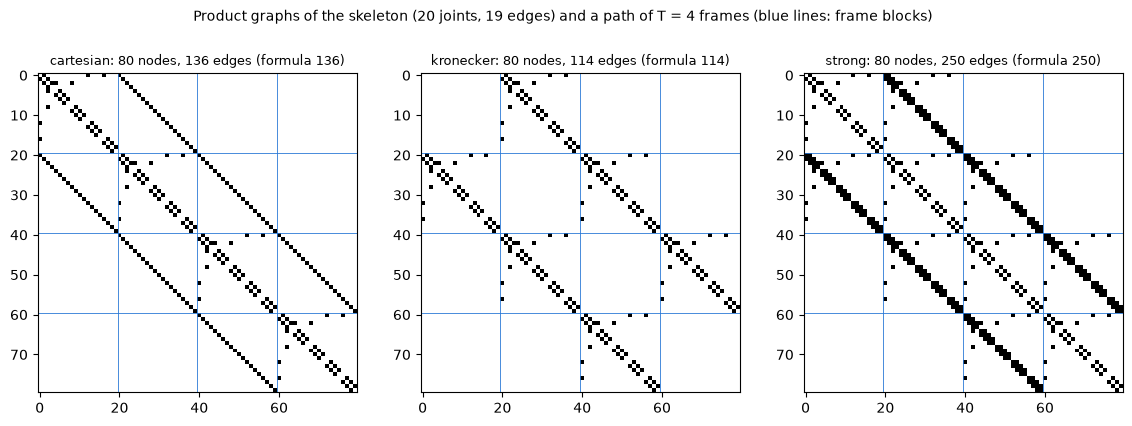

In [9]:
def path_graph(T):
    A = torch.zeros(T, T)
    idx = torch.arange(T - 1)
    A[idx, idx + 1] = A[idx + 1, idx] = 1.0
    return A

def product_graphs(A_S, T):
    A_T, I_T, I_S = path_graph(T), torch.eye(T), torch.eye(A_S.size(0))
    cartesian = torch.kron(A_T, I_S) + torch.kron(I_T, A_S)        # ★ KEY: same joint across frames + bones within a frame
    kronecker = torch.kron(A_T, A_S)                                 # ★ KEY: bone neighbours in the previous / next frame
    return {'cartesian': cartesian, 'kronecker': kronecker, 'strong': cartesian + kronecker}

E_S = len(BONES)
T_demo = 4
G_demo = product_graphs(A_SKEL, T_demo)
formula = {'cartesian': T_demo * E_S + (T_demo - 1) * V, 'kronecker': 2 * (T_demo - 1) * E_S}
formula['strong'] = formula['cartesian'] + formula['kronecker']
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
for ax, (kind, A) in zip(axes, G_demo.items()):
    ax.imshow(A, cmap='Greys', interpolation='nearest')
    ax.set_title(f'{kind}: {T_demo * V} nodes, {int(A.sum() / 2)} edges (formula {formula[kind]})', fontsize=9)
    for k in range(1, T_demo):
        ax.axhline(k * V - 0.5, color=COLORS['Paradigm'], lw=0.6); ax.axvline(k * V - 0.5, color=COLORS['Paradigm'], lw=0.6)
plt.suptitle(f'Product graphs of the skeleton ({V} joints, {E_S} edges) and a path of T = {T_demo} frames (blue lines: frame blocks)', fontsize=10)
plt.show()

For $T = 52$ the product graph has 1,040 nodes, and for long sequences it grows quickly, so we never build its adjacency matrix. 

One propagation step can be written with the two small matrices: $(\mathbf A_T\otimes\mathbf I_V)\,\mathbf h$ adds the values of the previous and the next frame, and $(\mathbf I_T\otimes\mathbf A_S)\,\mathbf h$ aggregates the bone neighbours in every frame. 

We check this against the dense matrix and look at the receptive field: how many space-time nodes does a node reach in $L$ hops?

cartesian: max |product_propagate - dense| = 4.8e-07
kronecker: max |product_propagate - dense| = 4.8e-07
strong   : max |product_propagate - dense| = 9.5e-07


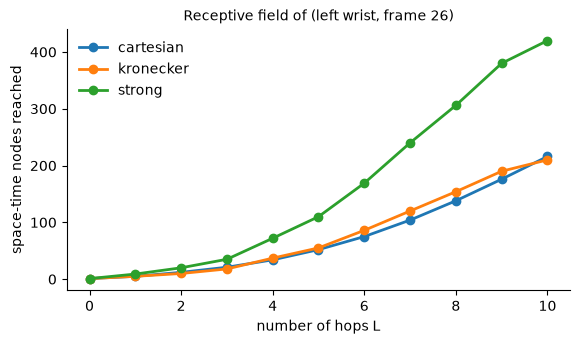

{'cartesian': 216, 'kronecker': 210, 'strong': 420}


In [10]:
def product_propagate(h, A_S, kind):
    # (A_prod + I) h on the product of the skeleton with the temporal path graph, without building A_prod.  h: [N, C, T, V]
    prev = F.pad(h, (0, 0, 1, 0))[:, :, :-1]                       # value of frame t-1, at frame t
    nxt = F.pad(h, (0, 0, 0, 1))[:, :, 1:]                         # value of frame t+1, at frame t
    temporal = prev + nxt                                          # (A_T (x) I) h
    out = h.clone()
    if kind in ('cartesian', 'strong'):
        out = out + temporal + torch.einsum('vw,nctw->nctv', A_S, h)              # + (I (x) A_S) h
    if kind in ('kronecker', 'strong'):
        out = out + torch.einsum('vw,nctw->nctv', A_S, temporal)                   # + (A_T (x) A_S) h
    return out

h = torch.randn(1, 2, T_demo, V)
for kind, A in G_demo.items():
    dense = ((A + torch.eye(T_demo * V)) @ h[0].permute(1, 2, 0).reshape(T_demo * V, 2)).view(T_demo, V, 2).permute(2, 0, 1)
    print(f'{kind:<9}: max |product_propagate - dense| = {(product_propagate(h, A_SKEL, kind)[0] - dense).abs().max():.1e}')

T_big, start = T_FRAMES, (26, 6)                                 # node: left wrist (6) at frame 26
L_max = 10
reach = {}
for kind in ['cartesian', 'kronecker', 'strong']:
    r = torch.zeros(1, 1, T_big, V); r[0, 0, start[0], start[1]] = 1
    counts = []
    for L in range(L_max + 1):
        counts.append(int((r > 0).sum()))
        r = (product_propagate(r, A_SKEL, kind) > 0).float()
    reach[kind] = counts
plt.figure(figsize=(6.5, 3.4))
for kind, c in reach.items():
    plt.plot(range(L_max + 1), c, marker='o', lw=2, label=kind)
plt.xlabel('number of hops L'); plt.ylabel('space-time nodes reached'); plt.legend(frameon=False)
plt.title('Receptive field of (left wrist, frame 26)', fontsize=10); plt.gca().spines[['top', 'right']].set_visible(False)
plt.show()
print({k: v[-1] for k, v in reach.items()})

* The edge counts match the formulas:
  * Cartesian $T|E_S| + (T-1)V$;
  * Kronecker $2(T-1)|E_S|$;
  * strong = their sum.

  `product_propagate` equals the dense product up to rounding ($< 10^{-6}$).

* Cartesian is the spatio-temporal graph of ST-GCN: the bones within a frame, plus the same joint in the previous and the next frame. Kronecker only has diagonal edges: a joint talks to its bone neighbours one frame earlier or later, never to itself. The strong product has both. Within a window of $\tau$ frames, it is the dense cross-spacetime graph of MS-G3D.

* The receptive field grows by at most one frame per hop: after 10 hops, the left wrist at frame 26 sees only frames 16–36 of the 52.
  * The Cartesian and Kronecker products reach about the same number of space-time nodes (216 and 210), because a hop moves either in time or in space (Cartesian), or both at once (Kronecker).
  * The strong product allows both kinds of hops and reaches twice as many (420).
  
* To see a whole clip, an STGNN needs many layers, temporal pooling, or temporal operators that span many frames at once (RNNs, long convolutions).

## 2.2. The general recipe: encoder → STMP layers → readout

Every STGNN as three operations:
$$\mathbf h^{i,0}_{t} = \mathrm{Encoder}\big(\mathbf x^i_t\big),\qquad \mathbf H^{l+1}_{t-W:t} = \mathrm{STMP}^l\big(\mathbf H^{l}_{t-W:t},\,\mathcal G\big),\qquad \hat y = \mathrm{Readout}\big(\mathbf H^{L}\big).$$

The spatio-temporal message-passing (STMP) blocks process sequences of node representations, not single vectors. 

How they mix the time and space dimensions defines three paradigms:

* Time-then-Space (TTS): encode the time series of every node into one vector, then propagate the vectors over the graph.
* Space-then-Time (STT): propagate over the graph at every time step, then encode each node's sequence of representations.
* Time-and-Space (T&S): time and space are mixed in every layer and cannot be factorised.

We use one encoder for all recurrent models: a linear layer on non-overlapping patches of 4 frames of a joint (12 numbers → 64 features). 

This shortens the sequences from 52 to 13 steps. 

The readout averages over steps and joints and applies a 2-layer MLP. 

The spatial operator is a GCN layer with $\hat{\mathbf A} = \mathbf D^{-1/2}(\mathbf A + \mathbf I)\mathbf D^{-1/2}$.

In [ ]:
class PatchEncoder(nn.Module):
    # Encoder of the recipe: a linear layer on patches of p frames of one joint.  [N, C, T, V] -> [N, V, T/p, H]
    def __init__(self, cin, hidden, p=4):
        super().__init__()
        self.p, self.lin = p, nn.Linear(cin * p, hidden)
    def forward(self, x):
        N, C, T, n = x.shape
        T = T // self.p * self.p                                   # drop the last frames if T is not a multiple of p
        return self.lin(x[:, :, :T].permute(0, 3, 2, 1).reshape(N, n, T // self.p, self.p * C))

class GCNLayer(nn.Module):
    # spatial message passing on the skeleton: A_hat h W, for any leading dimensions (..., V, C)
    def __init__(self, cin, cout):
        super().__init__()
        self.register_buffer('A', A_HAT)
        self.lin = nn.Linear(cin, cout)
    def forward(self, h, node_dim=-2):
        h = h.transpose(node_dim, -2)
        return self.lin(torch.einsum('vw,...wc->...vc', self.A, h)).transpose(node_dim, -2)

def readout_mlp(hidden, num_class=NUM_CLASS):
    return nn.Sequential(nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, num_class))

class TTS(nn.Module):
    # Time-then-Space: GRU over every joint's sequence -> One vector per joint -> GCN layers -> readout
    def __init__(self, cin=3, num_class=NUM_CLASS, hidden=64, gcn_layers=2):
        super().__init__()
        self.data_bn, self.encoder = DataBN(cin), PatchEncoder(cin, hidden)
        self.gru = nn.GRU(hidden, hidden, batch_first=True)
        self.gcns = nn.ModuleList([GCNLayer(hidden, hidden) for _ in range(gcn_layers)])
        self.readout = readout_mlp(hidden, num_class)

    def forward(self, x):
        h = self.encoder(self.data_bn(x))                          # [N, V, S, H]  (S = 13 steps)
        N, n, S, H = h.shape
        out, _ = self.gru(h.reshape(N * n, S, H))                  # 1. time: every joint separately (shared GRU)
        h = out.mean(1).view(N, n, H)                              # ★ KEY: one vector per joint
        for gcn in self.gcns:                                      # 2. space: message passing on V vectors only
            h = F.relu(gcn(h)) + h
        return self.readout(h.mean(1))

class STT(nn.Module):
    # Space-then-Time: GCN layers on every step -> GRU over every joint's sequence -> readout
    def __init__(self, cin=3, num_class=NUM_CLASS, hidden=64, gcn_layers=2):
        super().__init__()
        self.data_bn, self.encoder = DataBN(cin), PatchEncoder(cin, hidden)
        self.gcns = nn.ModuleList([GCNLayer(hidden, hidden) for _ in range(gcn_layers)])
        self.gru = nn.GRU(hidden, hidden, batch_first=True)
        self.readout = readout_mlp(hidden, num_class)

    def forward(self, x):
        h = self.encoder(self.data_bn(x))                          # [N, V, S, H]
        for gcn in self.gcns:                                      # 1. space: message passing at EVERY step
            h = F.relu(gcn(h, node_dim=1)) + h                     # ★ KEY: S times more graph convolutions than TTS
        N, n, S, H = h.shape
        out, _ = self.gru(h.reshape(N * n, S, H))                  # 2. time
        return self.readout(out.mean(1).view(N, n, H).mean(1))

## 2.3. Time-and-Space models

Graph-convolutional RNN (GCRNN). A GRU cell computes its gates with linear maps of the input and of the previous state. If we replace these maps by **message-passing** operators, the recurrence mixes time and space in every step:
$$\mathbf z_t = \sigma\big(\mathrm{MP}_z([\mathbf x_t, \mathbf h_{t-1}])\big),\quad \mathbf r_t = \sigma\big(\mathrm{MP}_r([\mathbf x_t, \mathbf h_{t-1}])\big),\quad \tilde{\mathbf h}_t = \tanh\big(\mathrm{MP}_h([\mathbf x_t, \mathbf r_t\odot\mathbf h_{t-1}])\big),\quad \mathbf h_t = \mathbf z_t\odot\mathbf h_{t-1} + (1-\mathbf z_t)\odot\tilde{\mathbf h}_t .$$

Spatio-temporal convolutional network (STCN), the alternate temporal and spatial convolutions in a "sandwich" block: a gated temporal convolution ($\mathbf P\odot\sigma(\mathbf Q)$, a GLU), a polynomial (Chebyshev, order 3) graph convolution, and a second gated temporal convolution.

Product-graph GCN. A plain GCN on the Cartesian product graph. Its temporal receptive field is tiny (one frame per layer), so we add temporal average pooling after layers 2 and 3.

The three recurrent models (TTS, STT, GCRNN) train more slowly than the convolutional ones, so we give them a 3× larger learning rate ($3\cdot10^{-3}$).

In [ ]:
class GCGRUCell(nn.Module):
    # GRU cell whose gates are graph convolutions
    def __init__(self, cin, hidden):
        super().__init__()
        self.register_buffer('A', A_HAT)
        self.gates = nn.Linear(cin + hidden, 2 * hidden)
        self.cand = nn.Linear(cin + hidden, hidden)

    def mp(self, h):                                               # message passing on [N, V, C]
        return torch.einsum('vw,nwc->nvc', self.A, h)

    def forward(self, x, h):                                       # x: [N, V, Cin], h: [N, V, H]
        z, r = torch.sigmoid(self.gates(self.mp(torch.cat([x, h], -1)))).chunk(2, -1)   # ★ KEY: gates = MP blocks
        h_tilde = torch.tanh(self.cand(self.mp(torch.cat([x, r * h], -1))))
        return z * h + (1 - z) * h_tilde

class GCRNN(nn.Module):
    def __init__(self, cin=3, num_class=NUM_CLASS, hidden=64):
        super().__init__()
        self.data_bn, self.encoder = DataBN(cin), PatchEncoder(cin, hidden)
        self.cell = GCGRUCell(hidden, hidden)
        self.readout = readout_mlp(hidden, num_class)

    def forward(self, x):
        h_in = self.encoder(self.data_bn(x))                       # [N, V, S, H]
        h = torch.zeros(h_in.size(0), V, h_in.size(-1), device=x.device)
        states = []
        for t in range(h_in.size(2)):                              # one GCRNN step per time step
            h = self.cell(h_in[:, :, t], h)
            states.append(h)
        return self.readout(torch.stack(states, 1).mean((1, 2)))

class GatedTCN(nn.Module):
    # P * sigmoid(Q): gated temporal convolution (GLU)
    def __init__(self, cin, cout, k=3):
        super().__init__()
        self.conv = nn.Conv2d(cin, 2 * cout, (k, 1), padding=((k - 1) // 2, 0))
    def forward(self, x):
        P, Q = self.conv(x).chunk(2, 1)
        return P * torch.sigmoid(Q)

def chebyshev_basis(A, K):
    # T_0 .. T_{K-1} of the rescaled Laplacian L~ = 2L/lambda_max - I with lambda_max ~ 2, i.e. L~ = -D^-1/2 A D^-1/2
    L = -normalize_adj(A, self_loops=False)
    Ts = [torch.eye(A.size(0)), L]
    for _ in range(2, K):
        Ts.append(2 * L @ Ts[-1] - Ts[-2])
    return torch.stack(Ts[:K])

class ChebConv(nn.Module):
    # sum_k T_k(L~) X W_k : a polynomial graph convolution reaching (K-1)-hop neighbours
    def __init__(self, cin, cout, K=3):
        super().__init__()
        self.register_buffer('T', chebyshev_basis(A_SKEL, K))
        self.K, self.cout = K, cout
        self.conv = nn.Conv2d(cin, K * cout, 1)
    def forward(self, x):
        N, C, T, n = x.shape
        h = self.conv(x).view(N, self.K, self.cout, T, n)
        return torch.einsum('nkctv,kwv->nctw', h, self.T)

class STConvBlock(nn.Module):
    #gated TCN -> Chebyshev graph conv -> gated TCN 
    def __init__(self, cin, cout, stride=1):
        super().__init__()
        self.t1, self.g, self.t2 = GatedTCN(cin, cout), ChebConv(cout, cout), GatedTCN(cout, cout)
        self.bn = nn.BatchNorm2d(cout)
        self.pool = nn.AvgPool2d((stride, 1)) if stride > 1 else nn.Identity()
        self.res = nn.Conv2d(cin, cout, 1) if cin != cout else nn.Identity()
    def forward(self, x):
        h = self.t2(F.relu(self.g(self.t1(x))))                    # ★ KEY: time -> space -> time in every block
        return self.pool(F.relu(self.bn(h) + self.res(x)))

class STCN(nn.Module):
    def __init__(self, cin=3, num_class=NUM_CLASS, channels=(64, 64, 128, 128), strides=(1, 1, 2, 1)):
        super().__init__()
        self.data_bn = DataBN(cin)
        blocks, c = [], cin
        for co, st in zip(channels, strides):
            blocks.append(STConvBlock(c, co, st))
            c = co
        self.blocks = nn.Sequential(*blocks)
        self.fc = nn.Linear(c, num_class)
    def forward(self, x):
        return self.fc(self.blocks(self.data_bn(x)).mean((2, 3)))

def product_degree(A_S, T, kind):
    dS = A_S.sum(1)
    dT = torch.full((T,), 2.0, device=A_S.device); dT[0] = dT[-1] = 1.0
    d = {'cartesian': dT[:, None] + dS[None], 'kronecker': dT[:, None] * dS[None]}
    d['strong'] = d['cartesian'] + d['kronecker']
    return d[kind] + 1.0                                           # + self-loop

class ProductGCN(nn.Module):
    # a plain GCN on the product graph:  D^-1/2 (A_prod + I) D^-1/2 H W, with temporal pooling
    def __init__(self, cin=3, num_class=NUM_CLASS, kind='cartesian', channels=(64, 64, 128, 128), pools=(1, 2, 2, 1)):
        super().__init__()
        self.kind = kind
        self.register_buffer('A_S', A_SKEL)
        self.data_bn = DataBN(cin)
        self.lins, self.bns, self.pools, c = nn.ModuleList(), nn.ModuleList(), [], cin
        for co, p in zip(channels, pools):
            self.lins.append(nn.Conv2d(c, co, 1)); self.bns.append(nn.BatchNorm2d(co)); self.pools.append(p)
            c = co
        self.fc = nn.Linear(c, num_class)
    def forward(self, x):
        h = self.data_bn(x)
        for lin, bn, p in zip(self.lins, self.bns, self.pools):
            d = product_degree(self.A_S, h.size(2), self.kind).pow(-0.5)
            h = F.relu(bn(lin(d * product_propagate(d * h, self.A_S, self.kind))))    # ★ KEY: one GCN layer on the product graph
            if p > 1:
                h = F.avg_pool2d(h, (p, 1))
        return self.fc(h.mean((2, 3)))

for name, make, lr in [('TTS (GRU -> GCN)', TTS, 3e-3), ('STT (GCN -> GRU)', STT, 3e-3), ('T&S: GCRNN', GCRNN, 3e-3),
                       ('T&S: STCN (Yu et al.)', STCN, 1e-3), ('T&S: product-graph GCN', ProductGCN, 1e-3)]:
    evaluate(name, make, family='Paradigm', lr=lr)

TTS (GRU -> GCN)                   accuracy 0.647 ± 0.012 |    39,042 parameters |  12.2 s per cross-view run (2 trainings)
STT (GCN -> GRU)                   accuracy 0.675 ± 0.025 |    39,042 parameters |  12.2 s per cross-view run (2 trainings)
T&S: GCRNN                         accuracy 0.607 ± 0.019 |    30,530 parameters |  56.7 s per cross-view run (2 trainings)
T&S: STCN (Yu et al.)              accuracy 0.711 ± 0.007 |   555,266 parameters |  23.9 s per cross-view run (2 trainings)
T&S: product-graph GCN             accuracy 0.557 ± 0.002 |    31,426 parameters |  21.3 s per cross-view run (2 trainings)


* All five models beat the spatial-only GCN (51.0%), but none of them beats the temporal-only TCN (75.3%).

* STT (67.5 ± 2.5%) and TTS (64.7 ± 1.2%) are close; STT is about 2.8 points ahead, which is within twice the seed spread. With mean pooling over the steps, both see the whole sequence. Both use the same small GRU and GCN (39k parameters).

* GCRNN (60.7%) is the weakest recurrent model and the slowest. Every step runs two graph convolutions, and the 13 steps must run one after the other.

* STCN (71.1 ± 0.7%) is the best model. It is convolutional: every layer looks at several frames at once, and the temporal pooling (stride) shortens the sequence for the next layers.

* The product-graph GCN (55.7%) is barely above the spatial-only model. Each of its layers only adds the previous and the next frame, so even with two poolings it sees only about ±10 frames, and it has only 31k parameters. A plain GCN on the product graph is a poor temporal model.

* The convolutional factorised block (spatial GCN + temporal convolution of 9 frames) is also the best design.

## 2.4. The cost of the paradigms

We measure the time of one training step (forward + backward, batch of 32 clips) when the clips are resampled to $T$ = 52 … 832 frames.

ms per training stepT = 52     T = 104    T = 208    T = 416    T = 832    
TTS                 7.5        7.4        7.5        16.0       7.9        
STT                 6.7        6.9        7.0        7.0        7.1        
GCRNN               36.7       70.8       134.6      288.1      532.6      
STCN                15.9       22.6       28.3       56.8       112.8      
product-graph GCN   14.5       13.8       13.2       15.6       28.5       


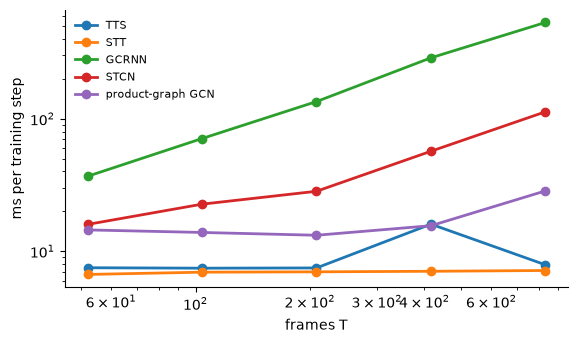

In [13]:
def step_time(make_model, T, reps=5):
    x = F.interpolate(X_ALL[:32].permute(0, 2, 3, 1).reshape(32, V * 3, -1), size=T, mode='linear')
    x = x.view(32, V, 3, T).permute(0, 3, 1, 2).contiguous().to(device)          # [32, T, V, 3]
    y = Y_ALL[:32].to(device)
    model = make_model().to(device)
    opt = torch.optim.Adam(model.parameters())
    for i in range(reps + 2):                                                     # 2 warm-up steps
        if i == 2:
            torch.cuda.synchronize() if device.type == 'cuda' else None
            t0 = time.time()
        loss = F.cross_entropy(model(x), y)
        opt.zero_grad(); loss.backward(); opt.step()
    torch.cuda.synchronize() if device.type == 'cuda' else None
    return (time.time() - t0) / reps * 1000

Ts = [52, 104, 208, 416, 832]
COST = {name: [step_time(make, T) for T in Ts] for name, make in
        [('TTS', TTS), ('STT', STT), ('GCRNN', GCRNN), ('STCN', STCN), ('product-graph GCN', ProductGCN)]}
print(f"{'ms per training step':<20}" + ''.join(f'T = {T:<7}' for T in Ts))
for name, c in COST.items():
    print(f'{name:<20}' + ''.join(f'{v:<11.1f}' for v in c))
plt.figure(figsize=(6.5, 3.6))
for name, c in COST.items():
    plt.plot(Ts, c, marker='o', lw=2, label=name)
plt.xscale('log'); plt.yscale('log'); plt.xlabel('frames T'); plt.ylabel('ms per training step')
plt.legend(frameon=False, fontsize=8); plt.gca().spines[['top', 'right']].set_visible(False)
plt.show()

# 3. ST-GCN

ST-GCN (Yan et al., AAAI 2018) was the first model to treat a skeleton sequence as a spatio-temporal graph end to end. 

Its block is the factorised STMP block: a spatial graph convolution on every frame, followed by a temporal convolution (kernel 9) on every joint, with a residual connection. 

What ST-GCN adds is how the neighbours are weighted.

## 3.1. Partition strategies

Unlike the pixels of an image, the neighbours of a joint have no natural order, so a convolution cannot give each of them its own weight. 

ST-GCN partitions the neighbourhood $\mathcal B(v_i)$ (the joint itself and its bone neighbours) into $K$ subsets and gives one weight matrix $W_k$ to each subset:

$$\mathbf f_{out} = \sum_{k=1}^{K}\boldsymbol\Lambda^{-\frac12}\mathbf A_k\boldsymbol\Lambda^{-\frac12}\,\mathbf f_{in}\,\mathbf W_k ,\qquad \sum_k \mathbf A_k = \mathbf A + \mathbf I .$$

* Uni-labeling ($K = 1$): one subset, i.e. a plain GCN.

* Distance partitioning ($K = 2$): the joint itself (distance 0) / its neighbours (distance 1).

* Spatial configuration ($K = 3$): the joint itself / the neighbours closer to the centre of gravity (centripetal) / the neighbours farther from it (centrifugal). Centripetal and centrifugal motions (e.g. arms moving towards / away from the body) get different weights.

We measure "closer to the centre" as the number of bones to a centre joint, the spine. 

A Euclidean distance would depend on the pose: in a standing pose the hanging hand is closer to the centre of the body than the shoulder.

uni      : K = 1, edges (incl. self-loops) per subset: [58]
distance : K = 2, edges (incl. self-loops) per subset: [20, 38]
spatial  : K = 3, edges (incl. self-loops) per subset: [20, 19, 19]
bones between every joint and the spine: {'hip centre': 1, 'spine': 0, 'shoulder centre': 1, 'head': 2, 'L shoulder': 2, 'L elbow': 3, 'L wrist': 4, 'L hand': 5, 'R shoulder': 2, 'R elbow': 3, 'R wrist': 4, 'R hand': 5, 'L hip': 2, 'L knee': 3, 'L ankle': 4, 'L foot': 5, 'R hip': 2, 'R knee': 3, 'R ankle': 4, 'R foot': 5}


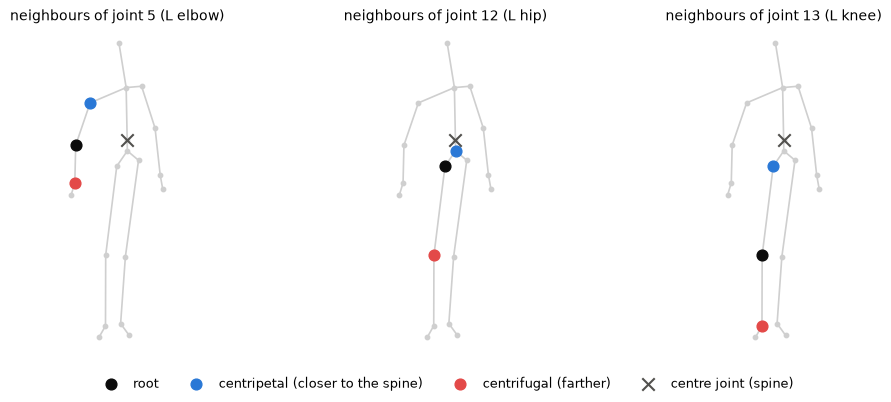

In [14]:
REF = CLIP['a01_s01_e00_v01']['x'][0]                       # a standing frame, used for the drawings (Section 1.3)
STAND = torch.tensor(REF - REF[1])                          # reference pose [V, 3], spine at the origin
CENTER_JOINT = 1                                            # the spine

def hops_to(A, center):
    # number of bones between every joint and the centre joint (breadth-first search)
    dist = torch.full((A.size(0),), -1)
    dist[center], frontier = 0, [center]
    while frontier:
        nxt = []
        for i in frontier:
            for j in A[i].nonzero().view(-1).tolist():
                if dist[j] < 0:
                    dist[j] = dist[i] + 1
                    nxt.append(j)
        frontier = nxt
    return dist

def partitions(A, strategy, center=CENTER_JOINT):
    # K x V x V matrices Lambda^-1/2 A_k Lambda^-1/2
    n = A.size(0)
    I = torch.eye(n)
    if strategy == 'uni':
        parts = [A + I]
    elif strategy == 'distance':
        parts = [I, A]
    else:                                                   # spatial configuration
        r = hops_to(A, center)                              # distance of every joint to the centre joint (in bones)
        root, centripetal, centrifugal = I.clone(), torch.zeros(n, n), torch.zeros(n, n)
        for i, j in A.nonzero().tolist():
            if r[j] < r[i]:
                centripetal[i, j] = 1                       # ★ KEY: neighbour j is closer to the centre than i
            elif r[j] > r[i]:
                centrifugal[i, j] = 1                       # ★ KEY: neighbour j is farther from the centre than i
            else:
                root[i, j] = 1
        parts = [root, centripetal, centrifugal]
    d = (A + I).sum(1).pow(-0.5)                            # Lambda: degree of the whole neighbourhood
    return torch.stack([d[:, None] * P * d[None, :] for P in parts])

PARTS = {s: partitions(A_SKEL, s) for s in ['uni', 'distance', 'spatial']}
for s, P in PARTS.items():
    print(f'{s:<9}: K = {P.size(0)}, edges (incl. self-loops) per subset: {[(p > 0).sum().item() for p in P]}')
print('bones between every joint and the spine:', dict(zip(JOINT_NAMES, hops_to(A_SKEL, CENTER_JOINT).tolist())))

# The three subsets of the spatial configuration for three joints
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
names = ['root', 'centripetal (closer to the spine)', 'centrifugal (farther)']
colors = ['#0b0b0b', COLORS['Paradigm'], COLORS['2s-AGCN']]
for ax, joint in zip(axes, [5, 12, 13]):
    for i, j in BONES:
        ax.plot(STAND[[i, j], 0], STAND[[i, j], 1], color='#cfcfcf', lw=1.2)
    ax.scatter(STAND[:, 0], STAND[:, 1], s=10, color='#cfcfcf')
    for k in range(3):
        nbrs = PARTS['spatial'][k][joint].nonzero().view(-1)
        ax.scatter(STAND[nbrs, 0], STAND[nbrs, 1], s=60, color=colors[k], label=names[k] if joint == 5 else None, zorder=3)
    ax.scatter(STAND[CENTER_JOINT, 0], STAND[CENTER_JOINT, 1], marker='x', s=80, color='#52514e', label='centre joint (spine)' if joint == 5 else None, zorder=4)
    ax.set_title(f'neighbours of joint {joint} ({JOINT_NAMES[joint]})', fontsize=10)
    ax.set_aspect('equal'); ax.axis('off')
fig.legend(loc='lower center', ncol=4, frameon=False, fontsize=9)
plt.show()

## 3.2. The ST-GCN layer and learnable edge importance

Not every bone matters equally for every action. ST-GCN multiplies every partition matrix by a learnable mask $\mathbf M_k$ (initialised at 1), element-wise:
$$\mathbf f_{out} = \sum_k \big(\boldsymbol\Lambda^{-\frac12}\mathbf A_k\boldsymbol\Lambda^{-\frac12}\odot \mathbf M_k\big)\,\mathbf f_{in}\,\mathbf W_k .$$

The mask can scale an existing edge but cannot create a new one (zeros of $\mathbf A_k$ stay zero).

The network uses the same backbone: `DataBN` → 4 blocks with 64, 64, 128, 128 channels (the third block halves the frames) → global average pooling over frames and joints → linear classifier. 

Every block is spatial module → BN → ReLU → temporal convolution (9 × 1) → + residual → ReLU. 

The models differ only in the spatial module.

In [15]:
class STBlock(nn.Module):
    # spatial module -> BN -> ReLU -> temporal conv (9 x 1) -> + residual -> ReLU
    def __init__(self, spatial, cin, cout, stride=1, residual=True):
        super().__init__()
        self.gcn, self.bn = spatial, nn.BatchNorm2d(cout)
        self.tcn = nn.Sequential(nn.Conv2d(cout, cout, (9, 1), (stride, 1), (4, 0)), nn.BatchNorm2d(cout), nn.Dropout(0.1))
        if not residual:
            self.res = lambda x: 0
        elif cin == cout and stride == 1:
            self.res = lambda x: x
        else:
            self.res = nn.Sequential(nn.Conv2d(cin, cout, 1, (stride, 1)), nn.BatchNorm2d(cout))

    def forward(self, x):
        return F.relu(self.tcn(F.relu(self.bn(self.gcn(x)))) + self.res(x))

class SkeletonNet(nn.Module):
    # DataBN -> 4 STBlocks (64, 64, 128, 128 channels; stride 2 in time in block 3) -> pooling -> linear
    def __init__(self, make_spatial, cin=3, num_class=NUM_CLASS, channels=(64, 64, 128, 128), strides=(1, 1, 2, 1)):
        super().__init__()
        self.data_bn = DataBN(cin)
        blocks, c = [], cin
        for i, (co, st) in enumerate(zip(channels, strides)):
            blocks.append(STBlock(make_spatial(c, co), c, co, st, residual=i > 0))
            c = co
        self.blocks = nn.ModuleList(blocks)
        self.fc = nn.Linear(c, num_class)

    def features(self, x):
        x = self.data_bn(x)
        for b in self.blocks:
            x = b(x)
        return x                                            # [N, C, T', V]

    def forward(self, x):
        return self.fc(self.features(x).mean((2, 3)))

class STGCNConv(nn.Module):
    # sum_k (Lambda^-1/2 A_k Lambda^-1/2 (*) M_k) X W_k
    def __init__(self, cin, cout, A_parts, importance=True):
        super().__init__()
        self.register_buffer('A', A_parts)
        self.K, self.cout = A_parts.size(0), cout
        self.conv = nn.Conv2d(cin, cout * self.K, 1)        # the K weight matrices W_k in one 1x1 convolution
        self.M = nn.Parameter(torch.ones_like(A_parts)) if importance else None

    def forward(self, x):                                   # x: [N, C, T, V]
        N, C, T, n = x.shape
        A = self.A * self.M if self.M is not None else self.A          # ★ KEY: learnable edge importance
        h = self.conv(x).view(N, self.K, self.cout, T, n)
        return torch.einsum('nkctv,kwv->nctw', h, A)                    # ★ KEY: aggregate every subset with its own W_k

for strategy in ['uni', 'distance', 'spatial']:
    for importance in [False, True]:
        model = evaluate(f'ST-GCN ({strategy}{", importance" if importance else ""})',
                         lambda: SkeletonNet(lambda ci, co: STGCNConv(ci, co, PARTS[strategy], importance)), family='ST-GCN')
STGCN_MODEL = model

ST-GCN (uni)                       accuracy 0.703 ± 0.008 |   409,794 parameters |  19.1 s per cross-view run (2 trainings)
ST-GCN (uni, importance)           accuracy 0.720 ± 0.013 |   411,394 parameters |  21.9 s per cross-view run (2 trainings)
ST-GCN (distance)                  accuracy 0.723 ± 0.012 |   439,042 parameters |  20.8 s per cross-view run (2 trainings)
ST-GCN (distance, importance)      accuracy 0.735 ± 0.008 |   442,242 parameters |  22.7 s per cross-view run (2 trainings)
ST-GCN (spatial)                   accuracy 0.764 ± 0.003 |   468,290 parameters |  19.9 s per cross-view run (2 trainings)
ST-GCN (spatial, importance)       accuracy 0.770 ± 0.002 |   473,090 parameters |  22.8 s per cross-view run (2 trainings)


## 3.3. What did the edge importance learn?

We average $\mathbf M_k$ over the layers and the partitions for every bone (model of the last fold: trained on view 1, tested on view 2). Values above 1 mean that the bone was amplified, below 1 that it was damped.

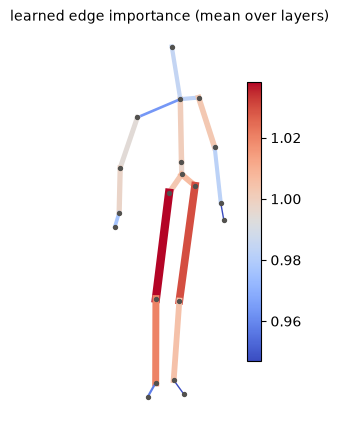

most amplified bones:  L hip-L knee (1.04), R hip-R knee (1.03), L knee-L ankle (1.02), hip centre-R hip (1.01), R knee-R ankle (1.01)
most damped bones:     L wrist-L hand (0.98), shoulder centre-L shoulder (0.96), L ankle-L foot (0.96), R ankle-R foot (0.95), R wrist-R hand (0.95)


In [16]:
def bone_scores(matrix):
    # mean of matrix[i, j] and matrix[j, i] for every bone
    return np.array([(matrix[i, j] + matrix[j, i]).item() / 2 for i, j in BONES])

def draw_bone_values(ax, values, title, cmap='coolwarm', vmin=None, vmax=None):
    vmin, vmax = (values.min() if vmin is None else vmin), (values.max() if vmax is None else vmax)
    cm = plt.get_cmap(cmap)
    for (i, j), v in zip(BONES, values):
        t = (v - vmin) / max(vmax - vmin, 1e-9)
        ax.plot(STAND[[i, j], 0], STAND[[i, j], 1], color=cm(t), lw=1 + 5 * t)
    ax.scatter(STAND[:, 0], STAND[:, 1], s=8, color='#52514e', zorder=3)
    ax.set_aspect('equal'); ax.axis('off'); ax.set_title(title, fontsize=10)
    sm = plt.cm.ScalarMappable(cmap=cm, norm=plt.Normalize(vmin, vmax))
    plt.colorbar(sm, ax=ax, fraction=0.04)

with torch.no_grad():
    M = torch.stack([(b.gcn.M * (b.gcn.A > 0)).sum(0) / (b.gcn.A > 0).sum(0).clamp(min=1) for b in STGCN_MODEL.blocks]).mean(0).cpu()
imp = bone_scores(M)
fig, ax = plt.subplots(figsize=(4.5, 5))
draw_bone_values(ax, imp, 'learned edge importance (mean over layers)')
plt.show()
order = np.argsort(-imp)
print('most amplified bones: ', ', '.join(f'{JOINT_NAMES[BONES[k][0]]}-{JOINT_NAMES[BONES[k][1]]} ({imp[k]:.2f})' for k in order[:5]))
print('most damped bones:    ', ', '.join(f'{JOINT_NAMES[BONES[k][0]]}-{JOINT_NAMES[BONES[k][1]]} ({imp[k]:.2f})' for k in order[-5:]))

# 4. 2s-AGCN 

ST-GCN has two limitations: the graph is fixed (the mask $\mathbf M_k$ can only rescale bones, so the two hands can never exchange messages directly), and it only uses the joint coordinates (first-order information). 2s-AGCN addresses both.

## 4.1. Adaptive graph convolution

The adjacency of every partition becomes the sum of three matrices:
$$\mathbf f_{out} = \sum_{k=1}^{K}\mathbf f_{in}\,(\mathbf A_k + \mathbf B_k + \mathbf C_k)\,\mathbf W_k$$

* $\mathbf A_k$: the physical skeleton (normalised partition, fixed), as in ST-GCN.

* $\mathbf B_k$: a free $V\times V$ matrix, learned from all the data (initialised at 0). It can create edges between any two joints.

* $\mathbf C_k$: a data-dependent graph, one per sample: two embeddings $\theta_k, \phi_k$ (1 × 1 convolutions) of the input, and a normalised similarity $\mathbf C_k = \mathrm{softmax}\big(\mathbf f_{in}^\top\mathbf W_{\theta_k}^\top\mathbf W_{\phi_k}\mathbf f_{in}\big)$. Every row of $\mathbf C_k$ sums to 1.

In [17]:
class AdaptiveConv(nn.Module):
    # sum_k (A_k + B_k + C_k) X W_k, C_k = softmax(theta_k(X)^T phi_k(X))  
    def __init__(self, cin, cout, A_parts, use_A=True, use_B=True, use_C=True, embed=16):
        super().__init__()
        self.K, self.cout, self.use_C = A_parts.size(0), cout, use_C
        self.register_buffer('A', A_parts if use_A else torch.zeros_like(A_parts))
        self.B = nn.Parameter(torch.zeros_like(A_parts)) if use_B else None
        if use_C:
            self.theta = nn.Conv2d(cin, embed * self.K, 1)
            self.phi = nn.Conv2d(cin, embed * self.K, 1)
        self.conv = nn.Conv2d(cin, cout * self.K, 1)
        self.last_C = None

    def forward(self, x):                                   # x: [N, C, T, V]
        N, C, T, n = x.shape
        A = self.A[None]
        if self.B is not None:
            A = A + self.B[None]                            # ★ KEY: B_k, shared by all samples
        if self.use_C:
            th = self.theta(x).view(N, self.K, -1, n)        # [N, K, embed*T, V]
            ph = self.phi(x).view(N, self.K, -1, n)
            Ck = F.softmax(torch.einsum('nkev,nkew->nkvw', th, ph) / th.size(2) ** 0.5, dim=-1)   # ★ KEY: C_k, one per sample
            self.last_C = Ck.detach()
            A = A + Ck
        h = self.conv(x).view(N, self.K, self.cout, T, n)
        return torch.einsum('nkctv,nkwv->nctw', h, A.expand(N, -1, -1, -1))

## 4.2. Bones: second-order information and two streams

A bone is the vector from a source joint to a target joint, $\mathbf e_{v_1, v_2} = (x_2 - x_1,\, y_2 - y_1,\, z_2 - z_1)$. It carries the direction and length of a limb, which the joint coordinates only give implicitly. 

We orient every bone away from a root joint: a breadth-first search over the skeleton from the spine gives every joint a parent, and the bone of joint $j$ is $\mathbf x_j - \mathbf x_{\mathrm{parent}(j)}$. 

This gives one bone per joint, so the bone stream can reuse the same graph (the root's bone is 0).

Two streams: one network on the joints (J-stream), one on the bones (B-stream), trained separately. 

At test time their softmax scores are added and the class with the highest fused score is predicted. 

`evaluate` stores the test probabilities of every clip, so the fusion needs no extra training.

In [18]:
def bfs_parents(A, root):
    parent = [-1] * A.size(0)
    parent[root], queue = root, [root]
    while queue:
        i = queue.pop(0)
        for j in A[i].nonzero().view(-1).tolist():
            if parent[j] == -1:
                parent[j] = i
                queue.append(j)
    return parent

PARENT = bfs_parents(A_SKEL, root=1)                        # rooted at the spine
assert -1 not in PARENT                                     # the skeleton is connected

def joints_to_bones(x):
    # bone of joint j = x_j - x_parent(j)   (x: [N, T, V, C])
    return x - x[:, :, PARENT]                              # ★ KEY: second-order information

class BoneStream(nn.Module):
    def __init__(self, net):
        super().__init__()
        self.net = net
    def forward(self, x):
        return self.net(joints_to_bones(x))

print('parent of every joint:', {JOINT_NAMES[j]: JOINT_NAMES[p] for j, p in enumerate(PARENT) if j in (0, 3, 7, 11, 15, 19)})
make_agcn = lambda: SkeletonNet(lambda ci, co: AdaptiveConv(ci, co, PARTS['spatial']))
AGCN_MODEL = evaluate('2s-AGCN: J-stream', make_agcn, family='2s-AGCN')
evaluate('2s-AGCN: B-stream', lambda: BoneStream(make_agcn()), family='2s-AGCN')

def fuse(names, new_name, family):
    # add the softmax scores of models that were evaluated with the same seeds and folds 
    probs = sum(RESULTS[n]['probs'] for n in names)
    accs = fold_accuracy(probs)
    RESULTS[new_name] = dict(acc=np.mean(accs), std=np.std(accs), params=sum(RESULTS[n]['params'] for n in names),
                             family=family, time=sum(RESULTS[n]['time'] for n in names), probs=probs)
    print(f'{new_name:<34} accuracy {np.mean(accs):.3f} ± {np.std(accs):.3f}')

fuse(['2s-AGCN: J-stream', '2s-AGCN: B-stream'], '2s-AGCN (J + B fusion)', '2s-AGCN')

parent of every joint: {'hip centre': 'spine', 'head': 'shoulder centre', 'L hand': 'L wrist', 'R hand': 'R wrist', 'L foot': 'L ankle', 'R foot': 'R ankle'}
2s-AGCN: J-stream                  accuracy 0.731 ± 0.018 |   498,338 parameters |  32.3 s per cross-view run (2 trainings)
2s-AGCN: B-stream                  accuracy 0.674 ± 0.003 |   498,338 parameters |  32.6 s per cross-view run (2 trainings)
2s-AGCN (J + B fusion)             accuracy 0.760 ± 0.011


## 4.3. What do $\mathbf B$ and $\mathbf C$ look like?

Plot the first layer of the J-stream (last fold, test view 2), the fixed $\mathbf A$, the learned $\mathbf B$ and the data-dependent $\mathbf C$ of one test clip, summed over the 3 partitions.

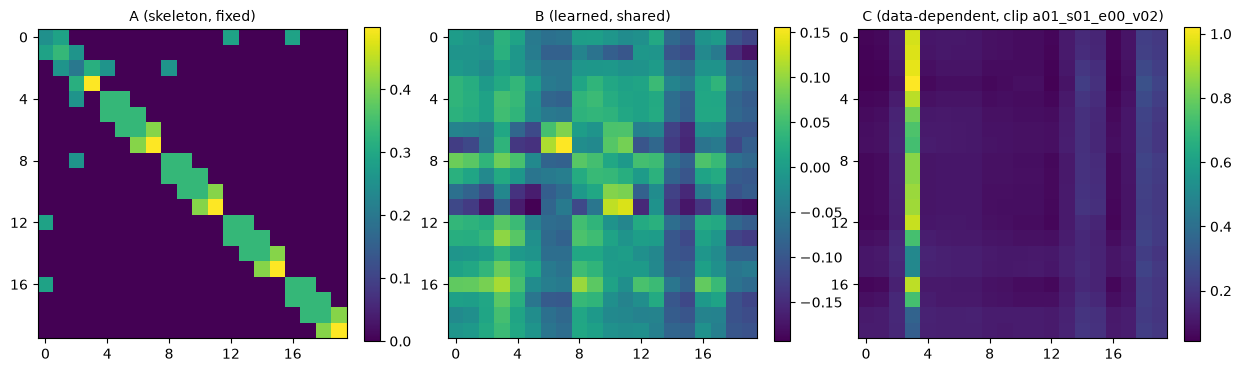

largest |B| entries: R hand <- L elbow (-0.19), R hand <- R foot (-0.18), R hand <- R ankle (-0.18), R hand <- shoulder centre (-0.18), spine <- R foot (-0.18), R hand <- L foot (-0.17)
share of C weight on physical neighbours (incl. self): 13.2%


In [19]:
clip = int(np.where(VIEW == 2)[0][0])                       # a test clip of the last fold
with torch.no_grad():
    AGCN_MODEL.eval()
    AGCN_MODEL(X_ALL[clip:clip + 1].to(device))
    layer = AGCN_MODEL.blocks[0].gcn
    mats = [layer.A.sum(0).cpu(), layer.B.sum(0).cpu(), layer.last_C[0].sum(0).cpu()]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for ax, M, title in zip(axes, mats, ['A (skeleton, fixed)', 'B (learned, shared)', f'C (data-dependent, clip {CLIPS[clip]["name"]})']):
    im = ax.imshow(M, cmap='viridis'); ax.set_title(title, fontsize=10)
    ax.set_xticks([0, 4, 8, 12, 16]); ax.set_yticks([0, 4, 8, 12, 16])
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.show()
Bm = mats[1].clone().fill_diagonal_(0)
top = torch.topk(Bm.abs().flatten(), 6).indices
print('largest |B| entries:', ', '.join(f'{JOINT_NAMES[i // V]} <- {JOINT_NAMES[i % V]} ({Bm.flatten()[i]:+.2f})' for i in top.tolist()))
print(f'share of C weight on physical neighbours (incl. self): {(mats[2] * (mats[0] > 0)).sum() / mats[2].sum():.1%}')

# 5. AS-GCN

AS-GCN generalises the skeleton graph with two kinds of links:

* S-links (structural links): higher-order neighbours of the skeleton, so that the hand is linked to the whole arm.

* A-links (actional links): action-specific dependencies between any two joints, inferred from the motion itself (e.g. the two hands when picking something up with both hands).

It also adds a future-pose prediction head as self-supervision.

## 5.1. S-links: L-hop structural graph convolution

ST-GCN aggregates only the 1-hop neighbours. 

The structural graph convolution uses the powers of the graph transition matrix $\hat{\mathbf A} = \mathbf D^{-1}\mathbf A$ up to order $L$, each with its own weights and its own learnable edge mask $\mathbf M_{st}^{(l)}$:
$$\mathbf X_{struc} = \sum_{l=1}^{L}\big(\hat{\mathbf A}^{l}\odot\mathbf M_{st}^{(l)}\big)\,\mathbf X\,\mathbf W_{st}^{(l)} .$$

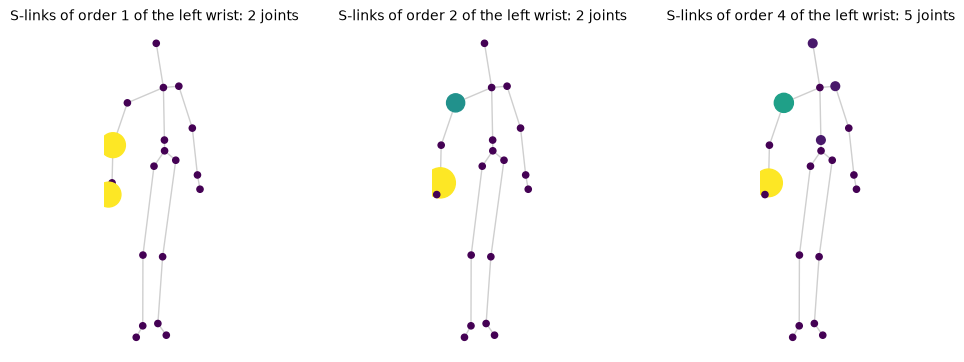

In [20]:
def transition_powers(A, L):
    # [P, P^2, ..., P^L] with P = D^-1 A the transition matrix of a random walk on the skeleton
    P = A / A.sum(1, keepdim=True)
    out, Pl = [], torch.eye(A.size(0))
    for _ in range(L):
        Pl = Pl @ P
        out.append(Pl.clone())
    return torch.stack(out)

P_POW = transition_powers(A_SKEL, 4)
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
for ax, l in zip(axes, [1, 2, 4]):
    w = P_POW[l - 1, 6]                                    # row of the left wrist
    for i, j in BONES:
        ax.plot(STAND[[i, j], 0], STAND[[i, j], 1], color='#cfcfcf', lw=1)
    ax.scatter(STAND[:, 0], STAND[:, 1], s=20 + 600 * w, c=w, cmap='viridis', vmin=0, vmax=0.5, zorder=3)
    ax.set_title(f'S-links of order {l} of the left wrist: {(w > 0).sum().item()} joints', fontsize=10)
    ax.set_aspect('equal'); ax.axis('off')
plt.show()

## 5.2. A-links: the A-link inference module 

The encoder of the A-link inference module (AIM) estimates, for every pair of joints $(i, j)$, the probability $\mathcal A_{i,j,c}$ that they are linked by an A-link of type $c$. It alternates between joints and links $K$ times:

* joint features $\mathbf p_i^{(0)}$: an MLP on the whole trajectory of joint $i$ (all $T$ frames),

* link features $\mathbf Q_{i,j}^{(k)} = f_e\big(\mathbf p_i^{(k)}, \mathbf p_j^{(k)}\big)$,

* joint features $\mathbf p_i^{(k+1)} = f_v\big(\mathrm{mean}_j\,\mathbf Q_{i,j}^{(k)}\big)$,

* after $K$ rounds: $\mathcal A_{i,j,:} = \mathrm{softmax}\big(\mathbf Q_{i,j}^{(K)}\big)$ over $C$ link types plus a "no link" type.

AS-GCN pre-trains the AIM as an encoder–decoder (the decoder predicts the next poses from the inferred links) and then fixes it. 

To keep the code short we train the AIM end to end with the rest of the network. 

The actional graph convolution then sums over the link types, $\mathbf X_{act} = \sum_{c}\hat{\mathcal A}_c\,\mathbf X\,\mathbf W_{act}^{(c)}$ with the row-normalised $\hat{\mathcal A}_c = \mathbf D_c^{-1}\mathcal A_c$, and the ASGC block combines both: $\mathbf X_{out} = \mathbf X_{struc} + \lambda\,\mathbf X_{act}$, with $\lambda = 0.5$.

In [21]:
class ALinkInference(nn.Module):
    # Encoder of the A-link inference module: joints -> links -> joints, K rounds -> link-type probabilities
    def __init__(self, cin, T, hidden=64, link_types=3, rounds=2):
        super().__init__()
        self.f_joint = nn.Sequential(nn.Linear(cin * T, hidden), nn.ReLU(), nn.Linear(hidden, hidden))
        self.f_e = nn.ModuleList([nn.Sequential(nn.Linear(2 * hidden, hidden), nn.ReLU(), nn.Linear(hidden, hidden)) for _ in range(rounds)])
        self.f_v = nn.ModuleList([nn.Sequential(nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, hidden)) for _ in range(rounds - 1)])
        self.out = nn.Linear(hidden, link_types + 1)        # + 1: the "no link" type

    def forward(self, x):                                   # x: [N, C, T, V]
        N, C, T, n = x.shape
        p = self.f_joint(x.permute(0, 3, 1, 2).reshape(N, n, C * T))     # p_i: the whole trajectory of joint i
        for k, f_e in enumerate(self.f_e):
            Q = f_e(torch.cat([p[:, :, None].expand(-1, -1, n, -1), p[:, None].expand(-1, n, -1, -1)], -1))   # ★ KEY: link features
            if k < len(self.f_v):
                p = self.f_v[k](Q.mean(2))                  # ★ KEY: joint features from the incident links
        probs = F.softmax(self.out(Q), -1)                  # [N, V, V, types + 1]
        return probs[..., 1:].permute(0, 3, 1, 2)            # drop "no link": [N, types, V, V]

class ASGCConv(nn.Module):
    # ASGC: sum_l (P^l (*) M_l) X W_l  (S-links, l = 0..L)  +  lambda * sum_c A_c X W_c  (A-links)
    def __init__(self, cin, cout, P_powers, link_types=3, lam=0.5):
        super().__init__()
        self.register_buffer('P', torch.cat([torch.eye(V)[None], P_powers]))
        self.L1, self.cout, self.types, self.lam = self.P.size(0), cout, link_types, lam
        self.M = nn.Parameter(torch.ones_like(self.P))
        self.conv_s = nn.Conv2d(cin, cout * self.L1, 1)
        self.conv_a = nn.Conv2d(cin, cout * link_types, 1)
        self.alinks = None                                  # set by ASGCN.forward for every batch

    def forward(self, x):
        N, C, T, n = x.shape
        hs = self.conv_s(x).view(N, self.L1, self.cout, T, n)
        out = torch.einsum('nlctv,lwv->nctw', hs, self.P * self.M)                  # structural links
        if self.alinks is not None:
            ha = self.conv_a(x).view(N, self.types, self.cout, T, n)
            A_act = self.alinks / self.alinks.sum(-1, keepdim=True).clamp(min=1e-6)   # D_c^-1 A_c: normalised A-links
            out = out + self.lam * torch.einsum('nkctv,nkwv->nctw', ha, A_act)          # actional links
        return out

## 5.3. Future-pose prediction head 

AS-GCN also predicts the next poses from the features of the backbone. 

This self-supervised task forces the network to capture the fine dynamics of the motion. 

We hide the last $F = 10$ frames: the network sees frames 1–42, classifies the clip, and a small MLP on the last time step of the backbone predicts the displacement of every joint over the next 10 frames. 

The loss is $\mathcal L = \mathcal L_{cls} + \mathcal L_{pred}$ (MSE).

In [22]:
class ASGCN(nn.Module):
    def __init__(self, cin=3, num_class=NUM_CLASS, T=T_FRAMES, L=4, link_types=3, use_alinks=True, predict=0):
        super().__init__()
        self.predict = predict
        self.backbone = SkeletonNet(lambda ci, co: ASGCConv(ci, co, transition_powers(A_SKEL, L), link_types), cin, num_class)
        self.aim = ALinkInference(cin, T - predict, link_types=link_types) if use_alinks else None
        if predict:                                         # future-pose prediction head
            self.head = nn.Sequential(nn.Linear(128 + cin, 128), nn.ReLU(), nn.Linear(128, predict * cin))

    def run(self, x):
        if self.aim is not None:
            alinks = self.aim(self.backbone.data_bn(x))     # one set of A-links per clip, used by every layer
            for b in self.backbone.blocks:
                b.gcn.alinks = alinks
        return self.backbone.features(x)

    def forward(self, x):
        if self.predict:
            x = x[:, :x.size(1) - self.predict]             # observed frames only
        return self.backbone.fc(self.run(x).mean((2, 3)))

    def forecast(self, past):
        h = self.run(past)
        last = past[:, -1]                                  # [N, V, C]: last observed pose
        delta = self.head(torch.cat([h[:, :, -1].permute(0, 2, 1), last], -1))
        return h, last[:, None] + delta.view(len(past), V, self.predict, -1).permute(0, 2, 1, 3)   # [N, F, V, C]

    def loss(self, x, y):
        if not self.predict:
            return F.cross_entropy(self(x), y)
        past, future = x[:, :-self.predict], x[:, -self.predict:]
        h, pred = self.forecast(past)
        return F.cross_entropy(self.backbone.fc(h.mean((2, 3))), y) + F.mse_loss(pred, future)   # ★ KEY: self-supervision

as_loss = lambda model, x, y: model.loss(x, y)
evaluate('AS-GCN: S-links only (L = 4)', lambda: ASGCN(use_alinks=False), family='AS-GCN')
ASGCN_MODEL = evaluate('AS-GCN: S + A-links', lambda: ASGCN(), family='AS-GCN')
ASGCN_PRED = evaluate('AS-GCN: S + A-links + prediction', lambda: ASGCN(predict=10), family='AS-GCN', loss_fn=as_loss)

# Prediction error on the test view of the last fold (view 2), compared with "the pose does not change"
H = T_FRAMES - 10
with torch.no_grad():
    ASGCN_PRED.eval()
    Xt = X_ALL[VIEW == 2].to(device)
    _, pred = ASGCN_PRED.forecast(Xt[:, :H])
    future = Xt[:, H:]
    err = lambda p: (p - future).norm(dim=-1).mean().item()
    print(f'\nfuture 10 frames, mean joint error (m): prediction head {err(pred):.4f} | constant pose (repeat frame {H}) {err(Xt[:, H - 1:H].expand_as(future)):.4f}')

# The strongest A-links of one test clip that are not bones
with torch.no_grad():
    ASGCN_MODEL.eval()
    links = ASGCN_MODEL.aim(ASGCN_MODEL.backbone.data_bn(X_ALL[VIEW == 2][:1].to(device)))[0].sum(0).cpu()
links = (links + links.T) / 2 * (1 - A_SKEL - torch.eye(V))
top = torch.topk(torch.triu(links, 1).flatten(), 6).indices.tolist()
print('strongest non-bone A-links:', ', '.join(f'{JOINT_NAMES[i // V]} - {JOINT_NAMES[i % V]}' for i in top))

AS-GCN: S-links only (L = 4)       accuracy 0.748 ± 0.002 |   622,530 parameters |  22.8 s per cross-view run (2 trainings)
AS-GCN: S + A-links                accuracy 0.734 ± 0.019 |   670,150 parameters |  40.1 s per cross-view run (2 trainings)
AS-GCN: S + A-links + prediction   accuracy 0.683 ± 0.009 |   688,996 parameters |  43.1 s per cross-view run (2 trainings)

future 10 frames, mean joint error (m): prediction head 0.1748 | constant pose (repeat frame 42) 0.1860
strongest non-bone A-links: hip centre - head, hip centre - L shoulder, hip centre - L wrist, hip centre - L hand, hip centre - shoulder centre, hip centre - L elbow


# 6. MS-G3D 

MS-G3D criticises two common designs:

1. Multi-scale aggregation with adjacency powers (as the S-links of AS-GCN) is biased towards close joints.

2. Factorised modelling (a spatial module, then a temporal module) is an indirect information flow: a joint cannot directly see another joint in another frame.

## 6.1. Biased weighting of adjacency powers 

On a graph with cycles and self-loops, a walk of length $k$ often comes back towards its start. 

So $\hat{\mathbf A}^k$ puts most of its weight on joints that are closer than $k$ hops, and the far joints get little weight. 

MS-G3D disentangles the scales with the $k$-adjacency matrix:

$$[\tilde{\mathbf A}_{(k)}]_{ij} = \begin{cases}1 & \text{if } d(v_i, v_j) = k\\ 1 & \text{if } i = j\ (\text{only in }\tilde{\mathbf A}_{(0)})\\ 0 & \text{otherwise}\end{cases}$$
where $d$ is the shortest-path distance in hops. Every scale then sees exactly one ring of neighbours.

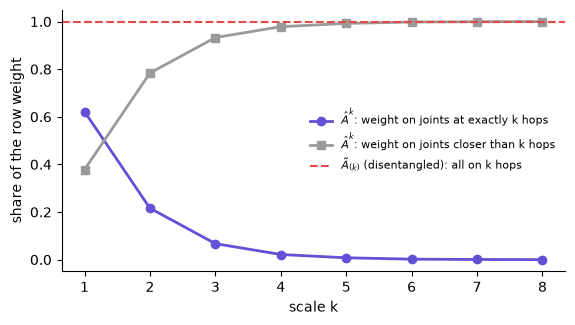

share on the k-hop ring: k=1: 0.62 | k=2: 0.22 | k=3: 0.07 | k=4: 0.02 | k=5: 0.01 | k=6: 0.00 | k=7: 0.00 | k=8: 0.00


In [23]:
def hop_distance(A):
    # shortest-path distance (in hops) between all pairs of joints
    n = A.size(0)
    D = torch.full((n, n), float('inf'))
    D.fill_diagonal_(0)
    reach = torch.eye(n)
    for k in range(1, n):
        reach = ((reach @ (A + torch.eye(n))) > 0).float()
        D[(reach > 0) & torch.isinf(D)] = k
    return D

HOPS = hop_distance(A_SKEL)

def k_adjacency(k):
    # A~_(k): 1 if the shortest path between i and j has exactly k hops; A~_(0) = I
    return (HOPS == k).float() if k > 0 else torch.eye(V)

A_hat = normalize_adj(A_SKEL)
ks = range(1, 9)
on_ring, closer = [], []
for k in ks:
    Ak = torch.matrix_power(A_hat, k)
    w = Ak / Ak.sum(1, keepdim=True)                        # weight distribution of every row
    on_ring.append(((HOPS == k) * w).sum(1).mean().item())  # share of the weight on the k-hop ring (mean over joints)
    closer.append(((HOPS < k) * w).sum(1).mean().item())
plt.figure(figsize=(6.5, 3.4))
plt.plot(ks, on_ring, marker='o', lw=2, color=COLORS['MS-G3D'], label='$\\hat A^k$: weight on joints at exactly k hops')
plt.plot(ks, closer, marker='s', lw=2, color='#9a9a9a', label='$\\hat A^k$: weight on joints closer than k hops')
plt.axhline(1, color=COLORS['2s-AGCN'], ls='--', lw=1.5, label='$\\tilde A_{(k)}$ (disentangled): all on k hops')
plt.xlabel('scale k'); plt.ylabel('share of the row weight'); plt.legend(frameon=False, fontsize=8)
plt.gca().spines[['top', 'right']].set_visible(False)
plt.show()
print('share on the k-hop ring:', ' | '.join(f'k={k}: {r:.2f}' for k, r in zip(ks, on_ring)))

## 6.2. Disentangled multi-scale aggregation and G3D

MS-GCN: one weight matrix per scale, with the normalised $k$-adjacency matrices,
$$\mathbf X^{(l+1)} = \sigma\Big(\sum_{k=0}^{K-1}\tilde{\mathbf D}_{(k)}^{-\frac12}\tilde{\mathbf A}_{(k)}\tilde{\mathbf D}_{(k)}^{-\frac12}\mathbf X^{(l)}\mathbf W_{(k)}^{(l)}\Big),$$
plus a learnable residual mask on every scale.

G3D: a sliding window of $\tau$ frames is treated as one graph with $\tau V$ nodes. Its adjacency tiles the skeleton adjacency in every block, $\tilde{\mathbf A}_{(\tau)} = \mathbf 1_{\tau\times\tau}\otimes\tilde{\mathbf A}$. 

Joint $i$ at frame $t$ is then linked to the neighbours of $i$ in all frames of the window, the dense cross-spacetime edges. 

Multi-scale aggregation runs on this window graph, and a learned linear map over the $\tau$ frames brings the result back to $V$ nodes.

The MS-G3D spatial module sums the factorised pathway (MS-GCN; the temporal convolution follows in the block) and the G3D pathway.

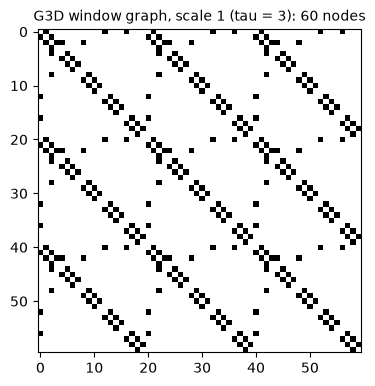

MS-GCN (powers of A^, K = 4)       accuracy 0.758 ± 0.006 |   503,938 parameters |  22.8 s per cross-view run (2 trainings)
MS-GCN (disentangled, K = 4)       accuracy 0.764 ± 0.007 |   503,938 parameters |  22.7 s per cross-view run (2 trainings)
MS-G3D (MS-GCN + G3D, tau = 3)     accuracy 0.772 ± 0.005 |   801,794 parameters |  35.7 s per cross-view run (2 trainings)


In [24]:
def disentangled_scales(K):
    # [I, A~_(1), ..., A~_(K-1)], each normalised: every scale sees exactly one ring of neighbours
    return [torch.eye(V)] + [normalize_adj(k_adjacency(k), self_loops=False) for k in range(1, K)]

def power_scales(K):
    # [I, A^, A^^2, ..., A^^(K-1)]: powers of the GCN operator (biased towards close joints)
    return [torch.eye(V)] + [torch.matrix_power(A_hat, k) for k in range(1, K)]

class MSGCN(nn.Module):
    # sum_k A_(k) X W_k with a learnable residual mask on every scale 
    def __init__(self, cin, cout, scales):
        super().__init__()
        self.register_buffer('A', torch.stack(list(scales)))
        self.K, self.cout = self.A.size(0), cout
        self.res = nn.Parameter(torch.zeros_like(self.A))
        self.conv = nn.Conv2d(cin, cout * self.K, 1)
    def forward(self, x):
        N, C, T, n = x.shape
        h = self.conv(x).view(N, self.K, self.cout, T, n)
        return torch.einsum('nkctv,kwv->nctw', h, self.A + self.res)

class G3D(nn.Module):
    # unified spatial-temporal graph conv on windows of tau frames
    def __init__(self, cin, cout, K=4, tau=3):
        super().__init__()
        self.tau = tau
        binary = [torch.eye(V)] + [k_adjacency(k) for k in range(1, K)]
        tiled = [normalize_adj(torch.ones(tau, tau).kron(b), self_loops=False) for b in binary]   # ★ KEY: 1_tau (x) A~_(k)
        self.gcn = MSGCN(cin, cout, tiled)
        self.collapse = nn.Conv3d(cout, cout, (1, tau, 1))  # tau*V nodes -> V nodes
    def forward(self, x):
        N, C, T, n = x.shape
        pad = (self.tau - 1) // 2
        win = F.pad(x, (0, 0, pad, self.tau - 1 - pad)).unfold(2, self.tau, 1)              # [N, C, T, V, tau]
        win = win.permute(0, 1, 2, 4, 3).reshape(N, C, T, self.tau * n)                       # ★ KEY: one graph of tau*V nodes per window
        h = self.gcn(win).view(N, -1, T, self.tau, n)
        return self.collapse(h).squeeze(3)

class MSG3DConv(nn.Module):
    # factorised pathway (MS-GCN) + G3D pathway, summed
    def __init__(self, cin, cout, K=4, tau=3, use_g3d=True):
        super().__init__()
        self.factorized = MSGCN(cin, cout, disentangled_scales(K))
        self.g3d = G3D(cin, cout, K, tau) if use_g3d else None
    def forward(self, x):
        out = self.factorized(x)
        return out + self.g3d(x) if self.g3d is not None else out

g = G3D(3, 8, K=2, tau=3)
plt.figure(figsize=(4.2, 4.2))
plt.imshow(g.gcn.A[1] > 0, cmap='Greys', interpolation='nearest')
plt.title(f'G3D window graph, scale 1 (tau = 3): {3 * V} nodes', fontsize=10)
plt.show()

evaluate('MS-GCN (powers of A^, K = 4)', lambda: SkeletonNet(lambda ci, co: MSGCN(ci, co, power_scales(4))), family='MS-G3D')
evaluate('MS-GCN (disentangled, K = 4)', lambda: SkeletonNet(lambda ci, co: MSGCN(ci, co, disentangled_scales(4))), family='MS-G3D')
evaluate('MS-G3D (MS-GCN + G3D, tau = 3)', lambda: SkeletonNet(lambda ci, co: MSG3DConv(ci, co)), family='MS-G3D');

# 7. DG-STGCN: spatio-temporal hypergraphs

Multi-view time-series hypergraph network goes beyond pairwise edges. 

Many motions involve groups of joints that move together: a whole arm, a whole leg. 

A hyperedge connects any number of nodes.

## 7.1. Incidence matrices

A hypergraph $\mathcal G = (\mathcal V, \mathcal E, \mathbf W)$ is described by its incidence matrix $\mathbf H\in\{0,1\}^{|\mathcal V|\times|\mathcal E|}$, $H_{v,e} = 1$ if node $v$ belongs to hyperedge $e$, and a diagonal matrix $\mathbf W$ of hyperedge weights. 

A node can belong to several hyperedges. We build the two spatial "views":

* Limb view (LCSH): 5 hyperedges, one per body part: trunk (with the head), left arm, right arm, left leg, right leg.
* Adjacent-joint view (AJSH): one hyperedge per joint, made of the joint and its skeleton neighbours. Along a limb this is 3 adjacent joints.

The hypergraph convolution (HGNN) is
$$\mathbf X' = \sigma\big(\mathbf D_v^{-\frac12}\mathbf H\mathbf W\mathbf D_e^{-1}\mathbf H^\top\mathbf D_v^{-\frac12}\,\mathbf X\,\boldsymbol\Theta\big),$$
with $\mathbf D_v$ the (weighted) node degrees and $\mathbf D_e$ the hyperedge sizes. 

It is the operator of the hypergraph Laplacian $\boldsymbol\Delta = \mathbf I - \mathbf D_v^{-\frac12}\mathbf H\mathbf W\mathbf D_e^{-1}\mathbf H^\top\mathbf D_v^{-\frac12}$. 

The messages flow node → hyperedge (mean over its nodes) → node.

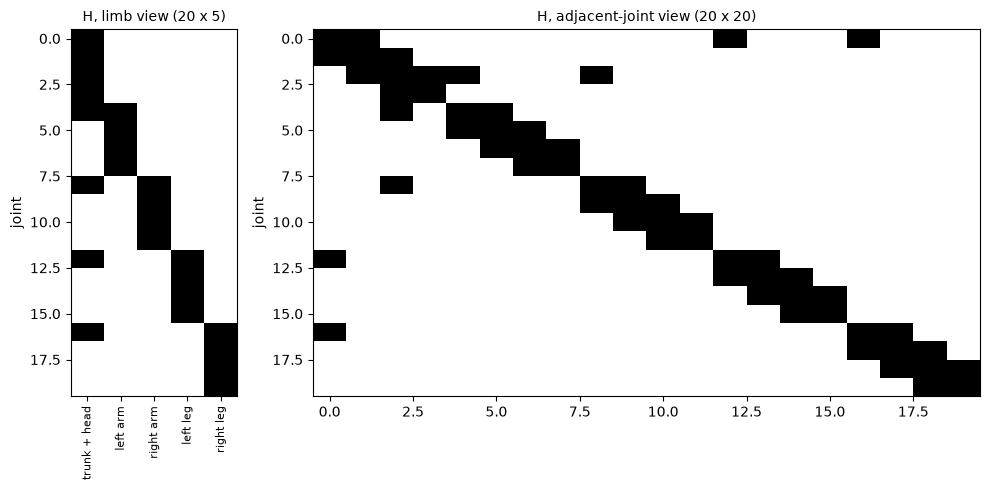

hyperedges = bones: max |HGNN operator - (I + D^-1/2 A D^-1/2) / 2| = 3.0e-08
node degree in the limb view (number of parts a joint belongs to): [1, 1, 1, 1, 2, 1, 1, 1, 2, 1, 1, 1, 2, 1, 1, 1, 2, 1, 1, 1]


In [25]:
BODY_PARTS = {'trunk + head': [0, 1, 2, 3, 4, 8, 12, 16], 'left arm': [4, 5, 6, 7], 'right arm': [8, 9, 10, 11],
              'left leg': [12, 13, 14, 15], 'right leg': [16, 17, 18, 19]}

def limb_incidence():
    H = torch.zeros(V, len(BODY_PARTS))
    for e, joints in enumerate(BODY_PARTS.values()):
        H[joints, e] = 1
    return H

def adjacent_incidence():
    return ((A_SKEL + torch.eye(V)) > 0).float()           # hyperedge e = joint e and its neighbours

def hypergraph_operator(H, w=None):
    # Dv^-1/2 H W De^-1 H^T Dv^-1/2
    w = torch.ones(H.size(1)) if w is None else w
    Dv = (H * w).sum(1).pow(-0.5)
    De = H.sum(0).pow(-1)
    return Dv[:, None] * ((H * w * De) @ H.T) * Dv[None, :]

H_LIMB, H_ADJ = limb_incidence(), adjacent_incidence()
fig, axes = plt.subplots(1, 2, figsize=(10, 5), gridspec_kw=dict(width_ratios=[1, 4]))
axes[0].imshow(H_LIMB, cmap='Greys', aspect='auto'); axes[0].set_title(f'H, limb view ({V} x 5)', fontsize=10)
axes[0].set_xticks(range(5)); axes[0].set_xticklabels(list(BODY_PARTS), rotation=90, fontsize=8)
axes[1].imshow(H_ADJ, cmap='Greys', aspect='auto'); axes[1].set_title(f'H, adjacent-joint view ({V} x {V})', fontsize=10)
for ax in axes: ax.set_ylabel('joint')
plt.tight_layout(); plt.show()

# A graph is a hypergraph whose hyperedges all have 2 nodes: with one hyperedge per bone, HGNN = (I + D^-1/2 A D^-1/2) / 2
H_bones = torch.zeros(V, len(BONES))
for e, (i, j) in enumerate(BONES):
    H_bones[[i, j], e] = 1
gap = (hypergraph_operator(H_bones) - (torch.eye(V) + normalize_adj(A_SKEL, self_loops=False)) / 2).abs().max()
print(f'hyperedges = bones: max |HGNN operator - (I + D^-1/2 A D^-1/2) / 2| = {gap:.1e}')
print('node degree in the limb view (number of parts a joint belongs to):', H_LIMB.sum(1).int().tolist())

* With one hyperedge per bone, the HGNN operator equals $\frac12(\mathbf I + \mathbf D^{-1/2}\mathbf A\mathbf D^{-1/2})$, a GCN operator. A graph is a hypergraph whose hyperedges all have 2 nodes, so the hypergraph convolution generalises the graph convolution.
* In the limb view, the shoulders and hips (joints 4, 8, 12, 16) belong to two hyperedges: they connect the trunk with the limbs. A message from the left hand reaches the whole left arm in one step, and the trunk in two.

## 7.2. Temporal hyperedges and the model

The temporal hypergraph groups consecutive frames: a hyperedge holds the same joint in $P$ consecutive frames, so a node exchanges information with the whole group at once. 

With non-overlapping groups the HGNN operator is just the mean over the group. 

We use two groupings shifted by $P/2$ so that every frame is also linked to its neighbours across group borders, and $P = 5$.

Spatio-temporal hypergraph module sums the two spatial views (each with its own $\boldsymbol\Theta$ and learnable hyperedge weights $\mathbf W$) and adds the temporal hypergraph convolution. 

The temporal convolution of the block follows as in all models.

In [26]:
class HyperConv(nn.Module):
    # X' = Dv^-1/2 H W De^-1 H^T Dv^-1/2 X Theta with learnable hyperedge weights W 
    def __init__(self, cin, cout, H):
        super().__init__()
        self.register_buffer('H', H)
        self.w = nn.Parameter(torch.zeros(H.size(1)))       # W = softplus(w) / log 2  (= 1 at the start)
        self.lin = nn.Conv2d(cin, cout, 1)
    def forward(self, x):
        G = hypergraph_operator(self.H, F.softplus(self.w) / math.log(2))
        return torch.einsum('vw,nctw->nctv', G, self.lin(x))

class TemporalHyperConv(nn.Module):
    # hyperedges = the same joint in P consecutive frames; two groupings shifted by P // 2
    def __init__(self, c, P=5):
        super().__init__()
        self.P, self.lin = P, nn.Conv2d(c, c, 1)
    def group_mean(self, x, shift):
        N, C, T, n = x.shape
        x = F.pad(x, (0, 0, shift, (-(T + shift)) % self.P), mode='replicate')
        m = x.view(N, C, -1, self.P, n).mean(3, keepdim=True).expand(-1, -1, -1, self.P, -1).reshape(N, C, -1, n)
        return m[:, :, shift:shift + T]                     # ★ KEY: node -> hyperedge (mean) -> node
    def forward(self, x):
        return self.lin(0.5 * (self.group_mean(x, 0) + self.group_mean(x, self.P // 2)))

class HyperSTConv(nn.Module):
    # limb view + adjacent-joint view (spatial hypergraphs) + temporal hypergraph
    def __init__(self, cin, cout, views=('limb', 'adjacent'), P=5):
        super().__init__()
        H = {'limb': H_LIMB, 'adjacent': H_ADJ}
        self.views = nn.ModuleList([HyperConv(cin, cout, H[v]) for v in views])
        self.temporal = TemporalHyperConv(cout, P) if P > 1 else None
    def forward(self, x):
        h = sum(view(x) for view in self.views)             # ★ KEY: multi-view spatial hypergraph
        return h + self.temporal(h) if self.temporal is not None else h

evaluate('Hypergraph (limb + adjacent views)', lambda: SkeletonNet(lambda ci, co: HyperSTConv(ci, co, P=1)), family='Hypergraph')
evaluate('Hypergraph (+ temporal hyperedges)', lambda: SkeletonNet(lambda ci, co: HyperSTConv(ci, co)), family='Hypergraph');

Hypergraph (limb + adjacent views) accuracy 0.690 ± 0.006 |   439,142 parameters |  43.6 s per cross-view run (2 trainings)
Hypergraph (+ temporal hyperedges) accuracy 0.698 ± 0.010 |   480,486 parameters |  51.5 s per cross-view run (2 trainings)


# 8. Summary: all models side by side

Every model was trained with the same protocol: cross-view (view 1 → view 2 and view 2 → view 1), 3 seeds, 40 epochs, the same augmentation.

model                                        accuracy  parameters    time
Majority class                           0.122 ± 0.000           0      0s
Temporal only (TCN, no graph)            0.753 ± 0.007     600,578     14s
Spatial only (GCN, no time)              0.509 ± 0.004      13,506     11s
TTS (GRU -> GCN)                         0.647 ± 0.012      39,042     12s
STT (GCN -> GRU)                         0.675 ± 0.025      39,042     12s
T&S: GCRNN                               0.607 ± 0.019      30,530     57s
T&S: STCN (Yu et al.)                    0.711 ± 0.007     555,266     24s
T&S: product-graph GCN                   0.557 ± 0.002      31,426     21s
ST-GCN (uni)                             0.703 ± 0.008     409,794     19s
ST-GCN (uni, importance)                 0.720 ± 0.013     411,394     22s
ST-GCN (distance)                        0.723 ± 0.012     439,042     21s
ST-GCN (distance, importance)            0.735 ± 0.008     442,242     23s
ST-GCN (spatial)          

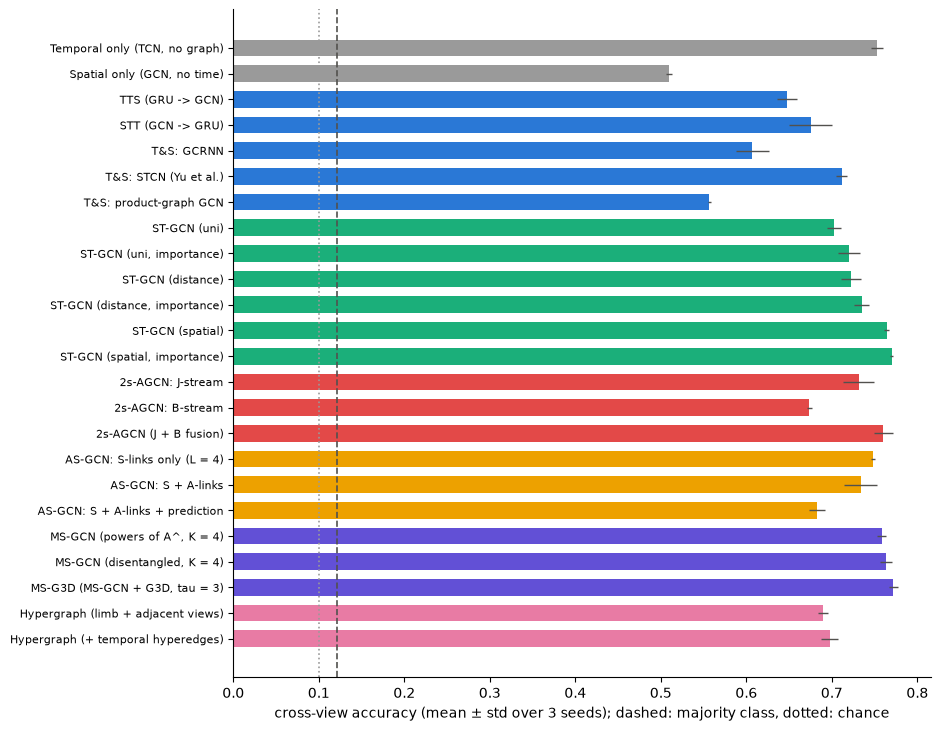

In [27]:
print(f"{'model':<36}{'accuracy':>17}{'parameters':>12}{'time':>8}")
for name, r in RESULTS.items():
    print(f"{name:<36}{r['acc']:>10.3f} ± {r['std']:.3f}{r['params']:>12,}{r['time']:>7.0f}s")

names = [n for n in RESULTS if n != 'Majority class']
fig, ax = plt.subplots(figsize=(9, 0.32 * len(names) + 1))
ax.barh(range(len(names)), [RESULTS[n]['acc'] for n in names], xerr=[RESULTS[n]['std'] for n in names],
        color=[COLORS[RESULTS[n]['family']] for n in names], height=0.65, error_kw=dict(lw=1, ecolor='#52514e'))
ax.axvline(RESULTS['Majority class']['acc'], color='#52514e', ls='--', lw=1.2)
ax.axvline(1 / NUM_CLASS, color='#9a9a9a', ls=':', lw=1.2)
ax.set_yticks(range(len(names))); ax.set_yticklabels(names, fontsize=8); ax.invert_yaxis()
ax.set_xlabel('cross-view accuracy (mean ± std over 3 seeds); dashed: majority class, dotted: chance')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

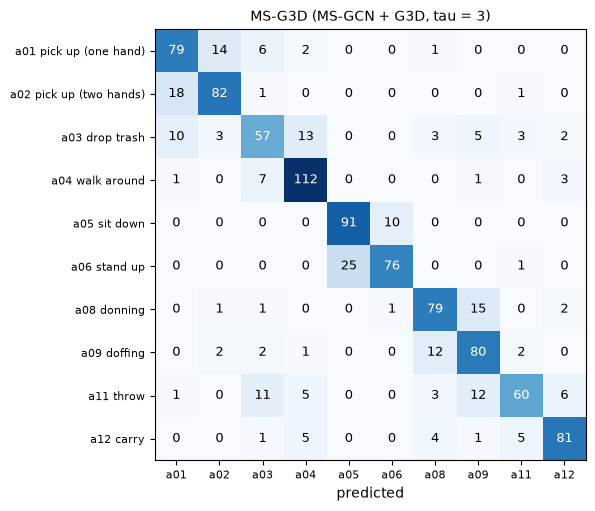

recall per class: a01 0.77 | a02 0.80 | a03 0.59 | a04 0.90 | a05 0.90 | a06 0.75 | a08 0.80 | a09 0.81 | a11 0.61 | a12 0.84


In [28]:
# Confusion matrix of the best model (probabilities averaged over the 3 seeds)
best = max(names, key=lambda n: RESULTS[n]['acc'])
pred = RESULTS[best]['probs'].mean(0).argmax(1)
conf = torch.zeros(NUM_CLASS, NUM_CLASS, dtype=torch.long)
for t, p in zip(Y_ALL.tolist(), pred.tolist()):
    conf[t, p] += 1
plt.figure(figsize=(7, 5.6))
plt.imshow(conf, cmap='Blues')
for i in range(NUM_CLASS):
    for j in range(NUM_CLASS):
        plt.text(j, i, int(conf[i, j]), ha='center', va='center', fontsize=9, color='white' if conf[i, j] > conf.max() / 2 else 'black')
plt.xticks(range(NUM_CLASS), ACTION_CODES, fontsize=8); plt.yticks(range(NUM_CLASS), [f'{c} {a}' for c, a in zip(ACTION_CODES, ACTIONS)], fontsize=8)
plt.xlabel('predicted'); plt.title(f'{best}', fontsize=10)
plt.show()
print('recall per class:', ' | '.join(f'{ACTION_CODES[c]} {conf[c, c] / conf[c].sum():.2f}' for c in range(NUM_CLASS)))